**SAPIANS** · SCC5819 · MÓDULO 10 — PFI · MOLNAR, CAP. 23

# Quanto o preditor depende de cada entrada?

PDP, ALE, interação e decomposição funcional descreviam a resposta do modelo.
A PFI passa da forma da resposta ao erro:
quanto o desempenho do **mesmo modelo** muda quando perdemos a ligação de uma
entrada com o restante da ficha e com o desfecho?

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) ·
[internals](pfi_internals.ipynb) ·
[Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/10-pfi/notebooks/pfi_walkthrough.ipynb)

---

**Objetivos.** Acompanhar a permutação sem retreino; distinguir Log loss, diferença
 e razão; interpretar ranking e SD; explicar permutações conjuntas e por subgrupos
sem confundi-las com causalidade ou com uma única importância verdadeira.

A aula do navegador é em inglês. O material de estudo segue em português.
As tabelas contêm os resultados reais agregados e um recorte didático real,
conferido separadamente. O recorte mostra previsões registradas do modelo fixo;
seu erro não é confundido com a importância calculada no teste completo.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import hashlib
import inspect
import io
import json
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss, mean_absolute_error
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                        str(REPO)], check=True, capture_output=True)
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_62_pfi as P
import srag_70_explain as K
import srag_72_pfi_presentation as Q
import srag_73_teaching_demo as H
import srag_75_pfi_figures as F

WORK = pathlib.Path(os.environ.get("PFI_WORK_DIR", tempfile.mkdtemp(prefix="pfi-module-"))).expanduser().resolve()
WORK.mkdir(parents=True, exist_ok=True)
assert not WORK.is_relative_to(REPO)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Fonte das figuras científicas:", SP.FONTE_ATUAL)
RECORD = json.loads((REPO / "modules/00-dataset/gold/pfi_ranking.json").read_text())
SOURCE = json.loads((REPO / "modules/00-dataset/gold/pfi_slide_explainer.json").read_text())
PUBLIC = Q.project_aggregates(SOURCE)
Q.validate_aggregates(PUBLIC)
COMMITTED = json.loads((REPO / "modules/10-pfi/lecture/pfi-interactive/data/pfi-aggregates.json").read_text())
assert PUBLIC == COMMITTED
print("Origem: registros do experimento e amostra compartilhada do curso.")
print("O ranking completo é lido do registro; o modelo é reconstruído e os traços desta aula são recalculados.")
print("Projeção agregada da apresentação coincide com a fonte:", PUBLIC == COMMITTED)
print("Python:", sys.version.split()[0])

Fonte das figuras científicas: Satoshi
Origem: registros do experimento e amostra compartilhada do curso.
O ranking completo é lido do registro; o modelo é reconstruído e os traços desta aula são recalculados.
Projeção agregada da apresentação coincide com a fonte: True
Python: 3.12.13


## §1 — Da base ao preditor fixo

O módulo 00 é dono do Bronze, Silver, Gold, da amostra e da seleção temporal.
Este módulo reutiliza esses artefatos. A busca de modelos **não é repetida** aqui:
os cards registrados são impressos para documentar o condicionamento.
O preditor é reconstruído da amostra e só então congelado para a explicação.

O modelo de referência não usa pesos de classe nem reamostragem. A comparação
 de balanceamento é um estudo separado; não modificamos a referência nesta aula.
O teste histórico já foi observado, portanto esta explicação é exploratória.

In [3]:
protocol = RECORD["protocol"]
study = PUBLIC["study"]
for label, value in [
    ("Coorte Gold", study["cohort_n"]),
    ("Treino usado no ajuste", study["train_sample_n"]),
    ("Entradas do modelo", study["input_n"]),
    ("Fim do treino temporal", study["train_end"]),
    ("Ano da validação", study["validation_year"]),
    ("Ano do teste", study["test_year"]),
    ("Repetições por variável", protocol["repeats"]),
    ("Semente", protocol["permutation_seed"]),
]:
    print(label + ":", str(value) if "temporal" in label or label.startswith("Ano ") else SP.pt_int(value))
print("Splits registrados:")
print(SP.tabela(pd.DataFrame.from_dict(study["splits"], orient="index").reset_index(names="split"), casas=6))
print("Busca registrada por família:")
print(SP.tabela(pd.DataFrame(study["scoreboard"]), casas=6))
print("Configurações avaliadas por família:", json.dumps(study["search_counts"]))
print("Bootstrap do protocolo de desempate:", SP.pt_int(study["bootstrap_repeats"]))
print("Modelo selecionado:", study["winner"])
print("Hiperparâmetros:", json.dumps(study["xgb_params"], ensure_ascii=False))
print("Regra da escolha:", study["selection_rule"])
print("Coorte:", study["cohort_rule"])
print("Balanceamento:", study["balancing"])
print("Ausências:", study["missing"])
print("Versões do experimento:", json.dumps(protocol["versions"]))
print("AUC do teste registrado:", SP.pt(study["test_auc"], 8))
print("Brier histórico do teste registrado (seleção preservada):", SP.pt(study["test_brier"], 8))
print("Log loss do teste registrado:", SP.pt(study["test_logloss"], 8))

sample_path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
assert hashlib.sha256(sample_path.read_bytes()).hexdigest() == protocol["sample_sha256"]
gold = M.load_gold(sample_path)
x, _, y = M.design_matrix(gold)
train_mask = (gold["split"] == "train").to_numpy()
test_mask = (gold["split"] == "test").to_numpy()
xe = x.loc[test_mask].reset_index(drop=True)
ye = y[test_mask]
assert dict(M.XGB_PARAMS) == protocol["xgb_params"]
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[train_mask], y[train_mask])
model_snapshot = bytes(model.get_booster().save_raw())
expected_structure = "d8cebf0e21f762aa8588bc1a819078d4e8071743f6e19207e6b0a64adf8523ac"
assert H.structure_sha256(model) == expected_structure == H.REFERENCE_STRUCTURE_SHA256
assert list(x.columns) == protocol["features"]
assert int(train_mask.sum()) == protocol["n_train"]
assert len(ye) == protocol["n_evaluation"] and int(ye.sum()) == protocol["events"]
print("SHA256 das decisões, cortes e categorias:", H.structure_sha256(model))
print("SHA256 dos bytes do preditor desta execução:", hashlib.sha256(model_snapshot).hexdigest())
print("Orçamento declarado de reconstrução em passos binary32 (ULP):", SP.pt_int(H.REFERENCE_PROBABILITY_ULPS))
print("O orçamento não é um teorema geral do XGBoost; dados, receita e regras de decisão são conferidos separadamente.")
original_x = xe.copy(deep=True)
original_y = ye.copy()
reconstructed = P.scores(ye, model.predict_proba(xe)[:, 1])
for metric in ("brier", "auc", "logloss"):
    H.reference_metric_interval(ye, np.asarray(model.predict_proba(xe)[:, 1], dtype=np.float64),
                                RECORD["original"][metric], metric=metric)
print("Treino efetivo:", SP.pt_int(train_mask.sum()))
print("Teste efetivo:", SP.pt_int(len(ye)), "; óbitos:", SP.pt_int(ye.sum()))
print("Métricas reconstruídas:", {k: SP.pt(v, 8) for k, v in reconstructed.items()})
print("Modelo fixo daqui em diante: nenhuma nova chamada de fit.")

Coorte Gold: 1.282.970
Treino usado no ajuste: 200.000
Entradas do modelo: 40
Fim do treino temporal: 2022
Ano da validação: 2023
Ano do teste: 2024
Repetições por variável: 50
Semente: 42
Splits registrados:
split letalidade_pct         n  obitos
 test      18,200000    16.142   2.945
train      31,400000 1.242.680 390.769
  val      18,900000    24.148   4.572
Busca registrada por família:
   model                    label      auc    brier
   dummy      Prevalence baseline 0,500000 0,168900
     lpm Linear probability model 0,723200 0,155200
   logit      Logistic regression 0,721400 0,154500
  arvore            Decision tree 0,704100 0,143400
floresta            Random forest 0,740300 0,145400
     xgb                  XGBoost 0,756400 0,135600
Configurações avaliadas por família: {"arvore": 24, "dummy": 1, "floresta": 10, "logit": 7, "lpm": 1, "xgb": 30}
Bootstrap do protocolo de desempate: 200
Modelo selecionado: xgb
Hiperparâmetros: {"n_estimators": 800, "max_depth": 4, "learnin

SHA256 das decisões, cortes e categorias: d8cebf0e21f762aa8588bc1a819078d4e8071743f6e19207e6b0a64adf8523ac
SHA256 dos bytes do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Orçamento declarado de reconstrução em passos binary32 (ULP): 8
O orçamento não é um teorema geral do XGBoost; dados, receita e regras de decisão são conferidos separadamente.
Treino efetivo: 200.000
Teste efetivo: 16.142 ; óbitos: 2.945
Métricas reconstruídas: {'brier': '0,13080778', 'logloss': '0,40901958', 'auc': '0,76444839'}
Modelo fixo daqui em diante: nenhuma nova chamada de fit.


### Comparações registradas e critérios de escolha

A seleção histórica comparou famílias pelo maior ROC-AUC de validação. Sua
log loss continua registrada como histórica; não convertemos retroativamente
essa busca em seleção por log loss. Uma revisão separada reajustou somente o
XGBoost dentro de cada estratégia de balanceamento.

A nova rodada compara as famílias sem reamostragem, mantendo a amostra e os
períodos e selecionando os parâmetros pelo menor log loss de validação, sem
arredondar. Seu pré-processamento aprende apenas no treino; a diferença para
a tabela histórica não isola somente a mudança da métrica. Constante e OLS
são referências sem busca, e OLS recebe clipping declarado para a avaliação.

As tabelas públicas são uma projeção explícita dos agregados do módulo 00.
Conferimos fontes, parâmetros, finalistas e orçamento antes de imprimir os
resultados. Este caderno lê o estudo concluído; não executa a busca novamente.
O preditor da PFI não é substituído silenciosamente por essa leitura.


In [4]:
historical_record = json.loads((REPO / Q.SELECTION_SOURCE).read_text())
review_record = json.loads((REPO / Q.BALANCE_SOURCE).read_text())
family_search_record = json.loads((REPO / Q.FAMILY_SEARCH_SOURCE).read_text())
selection_public = json.loads((REPO / Q.LESSON / Q.MODEL_SELECTION_DATA).read_text())
Q.validate_model_selection(selection_public, historical_record, review_record, family_search_record)
assert selection_public == Q.project_model_selection(historical_record, review_record, family_search_record)
print("Fontes agregadas: selection_metrics.json, sample_balance_search.json e sample_family_search.json.")
print("Projeção pública coincide com as fontes:", True)
historical = selection_public["historical"]
review = selection_public["review"]
family_pt = {"dummy": "Referência constante", "lpm": "Modelo linear de probabilidade",
             "logit": "Regressão logística", "arvore": "Árvore de decisão",
             "floresta": "Floresta aleatória", "xgb": "XGBoost"}
strategy_pt = {"plain": "Original / sem balanceamento", "weights": "Pesos de classe",
               "rus": "Redução da majoritária", "smotenc_restricted": "SMOTENC restrito"}
print("Seleção histórica: parâmetros escolhidos pelo maior ROC-AUC de validação.")
print("Famílias históricas:", SP.pt_int(len(historical["families"])))
print(SP.tabela(pd.DataFrame([{
    "modelo": family_pt[row["model"]],
    "log loss validação": row["validation_logloss"],
    "log loss teste": row["test_logloss"],
} for row in historical["families"]]), casas=4))
print("Precisão da fonte histórica:", SP.pt_int(4), "casas decimais; não acrescentamos casas ausentes.")
print("Vencedor histórico por AUC:", family_pt[historical["winner"]])
best_historical_loss = min(historical["families"], key=lambda row: row["validation_logloss"])
print("Menor log loss de validação entre esses finalistas:", family_pt[best_historical_loss["model"]])

print("Revisão concluída: somente XGBoost; menor log loss de validação sem arredondar.")
print("Estratégias:", SP.pt_int(len(review["strategies"])))
print("Configurações por estratégia:", SP.pt_int(review["candidates_per_strategy"]))
print("Total de ajustes:", SP.pt_int(review["candidates_per_strategy"] * len(review["strategies"])))
print(SP.tabela(pd.DataFrame([{
    "estratégia": strategy_pt[row["strategy"]],
    "log loss validação": row["validation_logloss"],
    "log loss teste": row["test_logloss"],
} for row in review["strategies"]]), casas=4))
print("Vencedor da revisão pela validação:", strategy_pt[review["winner"]])
print("Probabilidades recalibradas:", review["recalibrated"])
print("Teste utilizado para selecionar:", review_record["selection"]["test_used_for_selection"])
print("O teste já observado é exploratório; não altera a escolha.")

def parameter_text(value):
    if value is None:
        return "sem limite"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, int):
        return SP.pt_int(value)
    if isinstance(value, float):
        return SP.pt(value, 4)
    return str(value)

print("Parâmetros ajustados dos finalistas históricos (demais opções no protocolo de origem):")
print(SP.tabela(pd.DataFrame([{
    "modelo": family_pt[row["model"]], "parâmetro": key, "valor": parameter_text(value),
} for row in historical["families"] for key, value in row["params"].items()])))
print("Parâmetros ajustados dos finalistas da revisão:")
print(SP.tabela(pd.DataFrame([{
    "estratégia": strategy_pt[row["strategy"]], "parâmetro": key, "valor": parameter_text(value),
} for row in review["strategies"] for key, value in row["params"].items()])))
selected_review = next(row for row in review["strategies"] if row["strategy"] == review["winner"])
print("Parâmetros do vencedor da revisão:")
print(SP.tabela(pd.DataFrame([{
    "parâmetro": key, "valor": parameter_text(value),
} for key, value in selected_review["params"].items()])))
historical_xgb = next(row for row in historical["families"] if row["model"] == "xgb")
print("Hiperparâmetros originais do XGBoost retidos:", selected_review["params"] == historical_xgb["params"])
print("A revisão de balanceamento reajustou somente o XGBoost; o estudo de famílias é separado.")

current = selection_public["family_search"]
print("Nova comparação por família: sem reamostragem, preparação somente no treino.")
print("Critério: menor log loss de validação sem arredondar; teste exploratório posterior.")
print(SP.tabela(pd.DataFrame([{
    "modelo": family_pt[row["model"]], "candidatos": row["candidate_count"],
    "log loss validação": row["validation_logloss"], "log loss teste": row["test_logloss"],
} for row in current["families"]]), casas=4))
print("Candidatos de todas as famílias:", SP.pt_int(sum(row["candidate_count"] for row in current["families"])))
print("Vencedor na validação:", family_pt[current["winner"]])
print("Parâmetros dos finalistas escolhidos por log loss:")
print(SP.tabela(pd.DataFrame([{
    "modelo": family_pt[row["model"]], "parâmetro": key, "valor": parameter_text(value),
} for row in current["families"] for key, value in row["params"].items()])))
print("Mudanças de parâmetros em relação aos finalistas históricos por AUC:")
print(SP.tabela(pd.DataFrame([{
    "modelo": family_pt[row["model"]],
    "parâmetros diferentes": row["params"] != next(old for old in historical["families"] if old["model"] == row["model"])["params"],
} for row in current["families"]])))
print("Vencedor da nova seleção coincide com a família da referência PFI:", current["winner"] == PUBLIC["study"]["winner"])
print("Constante e OLS são referências sem tuning; OLS não foi ajustado minimizando log loss.")
print("O orçamento é específico por família, não uma igualdade de capacidade de otimização.")
print("Não há recalibração nem demonstração de melhor algoritmo universal.")

print("Novos ajustes de famílias:", SP.pt_int(sum(row["origin"]["kind"] == "fitted_phase54" for row in family_search_record["validation_candidates"])))
print("Candidatos XGBoost reutilizados, auditados:", SP.pt_int(sum(row["origin"]["kind"] == "imported_phase53_plain" for row in family_search_record["validation_candidates"])))
forest_finalist = next(row for row in family_search_record["selection"]["finalists"] if row["family"] == "floresta")
print("Árvores fixas na floresta, fora da busca:", SP.pt_int(forest_finalist["effective_params"]["n_estimators"]))


Fontes agregadas: selection_metrics.json, sample_balance_search.json e sample_family_search.json.
Projeção pública coincide com as fontes: True
Seleção histórica: parâmetros escolhidos pelo maior ROC-AUC de validação.
Famílias históricas: 6
                        modelo log loss validação log loss teste
          Referência constante             0,5246         0,5192
Modelo linear de probabilidade             0,5091         0,4978
           Regressão logística             0,4646         0,4422
             Árvore de decisão             0,4481         0,4476
            Floresta aleatória             0,4563         0,4464
                       XGBoost             0,4209         0,4090
Precisão da fonte histórica: 4 casas decimais; não acrescentamos casas ausentes.
Vencedor histórico por AUC: XGBoost
Menor log loss de validação entre esses finalistas: XGBoost
Revisão concluída: somente XGBoost; menor log loss de validação sem arredondar.
Estratégias: 4
Configurações por estratégia: 30

**O que olhar.** A primeira tabela conserva os finalistas da seleção por AUC;
a segunda compara estratégias de um único tipo de modelo, com novo ajuste por
log loss. Manter a configuração original é a conclusão desta revisão, não uma
prova de que qualquer balanceamento seria pior. A avaliação do teste permanece
exploratória, com probabilidades sem recalibração.


**O que olhar.** O ano define a separação temporal. A PFI usa somente os registros
 de avaliação e o modelo já ajustado. Unknown é uma categoria preservada; não é
convertida em ausência clínica.

## §2 — O erro original: log loss

Cada ficha tem um desfecho observado. Perguntamos quanto de probabilidade o
modelo atribuiu **ao desfecho que realmente ocorreu**. Para óbito, usamos
$p_i$; para sobrevida, $1-p_i$. A perda da ficha é o negativo do logaritmo
natural dessa probabilidade; a perda do conjunto é a média:

$$E_{orig}=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\ln(p_i)+(1-y_i)\ln(1-p_i)\right].$$

Quanto menor a probabilidade atribuída ao desfecho ocorrido, maior a penalidade.
Errar com muita confiança custa mais. A log loss é não negativa e não tem
limite superior finito. A implementação corta probabilidades nos limites da
precisão float64 para evitar logaritmo de zero. O limiar de classificação
não entra nessa conta.

Molnar usa log loss no exemplo de classificação de pinguins. Escolhemos essa
régua por aderência à referência e pela narrativa por ficha, após comparar
as métricas sem alterar o modelo. Ela avalia qualidade probabilística,
**não exclusivamente calibração**; curvas de calibração continuam necessárias.


In [5]:
p_original = np.asarray(model.predict_proba(xe)[:, 1], dtype=np.float64)
individual_losses = H.individual_logloss(ye, p_original)
baseline = float(log_loss(ye, p_original))
np.testing.assert_allclose(individual_losses.mean(), baseline, rtol=0, atol=1e-15)
print("Log loss original no teste completo:", SP.pt(baseline, 8))
print("Média manual e função da biblioteca coincidem:",
      bool(np.isclose(individual_losses.mean(), baseline, atol=1e-15, rtol=0)))
print("Limite inferior do Log loss binário:", SP.pt(0, 0))
print("Log loss não possui limite superior finito; usa logaritmo natural.")
print("Menor Log loss é melhor. A referência é compartilhada por todas as variáveis.")

Log loss original no teste completo: 0,40901958
Média manual e função da biblioteca coincidem: True
Limite inferior do Log loss binário: 0
Log loss não possui limite superior finito; usa logaritmo natural.
Menor Log loss é melhor. A referência é compartilhada por todas as variáveis.


**O que olhar.** A referência é uma média do teste completo. Seu valor se repete
 nos gráficos porque o modelo e o conjunto original são os mesmos.

## §3 — Copiar, permutar, prever e restaurar

A fonte executável mora em `tools/srag_70_explain.py`, como nos outros módulos.
Mostramos o código que vai rodar: cada ordem leva valores de uma linha doadora
 para a linha receptora, mantendo alvos, índice e entradas não selecionadas.
Não retiramos uma coluna, não alteramos hiperparâmetros e não retreinamos.

A mesma coleção de ordens é usada nos experimentos separados. O experimento de
saturação **começa da matriz original**, sem carregar a idade já permutada.

In [6]:
print(inspect.getsource(K.permutar_colunas))
print(inspect.getsource(K.trace_pfi))
rng = np.random.default_rng(protocol["permutation_seed"])
orders = [rng.permutation(len(xe)) for _ in range(protocol["repeats"])]
traces = {}
for feature in ("idade_anos", "saturacao"):
    before, after = K.trace_pfi(model, xe, ye, feature, orders, log_loss)
    np.testing.assert_allclose(before, baseline, rtol=0, atol=1e-15)
    stored = next(r for r in RECORD["rows"] if r["feature"] == feature)["metrics"]["logloss"]
    discrepancy = float(np.max(np.abs(after - np.asarray(stored["after"]))))
    assert discrepancy < 5e-5
    traces[feature] = after
    print(feature, "; erro após médio:", SP.pt(after.mean(), 8),
          "; aumento médio:", SP.pt((after - baseline).mean(), 8),
          "; SD amostral:", SP.pt(after.std(ddof=1), 8),
          "; maior desvio do registro:", SP.pt_sig(discrepancy))
age_delta = traces["idade_anos"] - baseline
repeat_table = pd.DataFrame({
    "repetição": np.arange(1, len(orders) + 1),
    "Log loss original": baseline,
    "Log loss após permuta": traces["idade_anos"],
    "aumento": age_delta,
    "média acumulada": [age_delta[:k].mean() for k in range(1, len(orders) + 1)],
    "SD acumulado": [np.nan if k == 1 else age_delta[:k].std(ddof=1)
                    for k in range(1, len(orders) + 1)],
})
print("Traço completo de idade; SD de uma única repetição é indefinido:")
print(SP.tabela(repeat_table, casas=8))
pd.testing.assert_frame_equal(xe, original_x)
np.testing.assert_array_equal(ye, original_y)
assert bytes(model.get_booster().save_raw()) == model_snapshot
print("Entradas, alvos e modelo originais preservados:", True)

def permutar_colunas(
    x_eval: pd.DataFrame,
    colunas: str | tuple[str, ...] | list[str],
    ordem,
) -> pd.DataFrame:
    """Matriz original copiada, com somente as colunas indicadas movidas.

    `ordem[i]` é a posição da linha doadora para a linha de destino `i`.
    O índice de pandas não define esse transporte: `set_axis` repõe o
    índice de destino depois da seleção posicional, preservando inclusive
    categorias nativas. A matriz recebida nunca é modificada.

    Uma coluna implementa a permutação marginal. Várias colunas recebem a
    mesma ordem, preservando as combinações/tuplas observadas entre elas. Para
    subgrupos, o chamador fornece uma bijeção cujos doadores pertencem ao
    mesmo grupo que os destinos; esta função não infere os grupos nem uma
    distribuição condicional.
    """
    selecionadas = (colunas,) if isinstance(colunas, str) else tuple(colunas)
    if not selecionadas or len(set(selecionadas)) != len(selecionadas):
        raise ValueError("Indi

idade_anos ; erro após médio: 0,49365325 ; aumento médio: 0,08463367 ; SD amostral: 0,00265889 ; maior desvio do registro: 0,00


saturacao ; erro após médio: 0,42116321 ; aumento médio: 0,01214364 ; SD amostral: 0,00088863 ; maior desvio do registro: 0,00
Traço completo de idade; SD de uma única repetição é indefinido:
repetição Log loss original Log loss após permuta    aumento média acumulada SD acumulado
        1        0,40901958            0,49139918 0,08237960      0,08237960           NA
        2        0,40901958            0,49798639 0,08896681      0,08567321   0,00465786
        3        0,40901958            0,49602817 0,08700859      0,08611833   0,00338264
        4        0,40901958            0,49560706 0,08658748      0,08623562   0,00277186
        5        0,40901958            0,49410940 0,08508982      0,08600646   0,00245458
        6        0,40901958            0,49507703 0,08605746      0,08601496   0,00219554
        7        0,40901958            0,49342773 0,08440815      0,08578542   0,00209424
        8        0,40901958            0,49715082 0,08813124      0,08607864   0,0021088

Entradas, alvos e modelo originais preservados: True


### Ver uma janela real da primeira permutação do teste completo

Conservamos as mesmas fichas históricas como receptores visíveis: primeiras
fichas adultas por desfecho no teste, depois na ordem original da base.
A tabela mostra idade e saturação; o modelo recebe todas as entradas originais.
O recorte selecionado pelo desfecho não representa a população do teste.

**Correção do mecanismo didático.** A ordem manual histórica trocava valores
somente entre fichas de mesmo desfecho neste recorte. Seus números permanecem
no registro para auditoria. Agora a tabela é uma janela da primeira ordem
aleatória do experimento global: os doadores vêm do teste inteiro, e não
somente das fichas visíveis. A ordem é fixada pelo protocolo antes de medir
a perda. Nenhum sorteio foi escolhido porque fez o erro subir ou cair.

O registro histórico de probabilidades fica intacto, assim como as idades,
saturação e desfechos. Refazer o ajuste em outra plataforma pode mudar os
últimos bits dos pesos e das probabilidades. Antes de comparar números,
conferimos exatamente a receita, os dados e todas as regras de decisão,
incluindo a codificação categórica. As probabilidades históricas usam um
orçamento declarado em passos de `float32` (ULP); as perdas recebem os
intervalos derivados desses passos. Isso é um contrato de regressão desta
receita, não uma garantia universal do XGBoost. Dentro da mesma execução,
o preditor permanece fixo e o transporte independente continua exato.
As previsões permutadas mudam porque elas agora recebem os valores realmente
usados naquela repetição global. A média de perda do recorte é impressa aqui
somente para auditoria. O gráfico da apresentação usa o erro global, a primeira
repetição identificada e a média e SD de todas as repetições registradas.


In [7]:
# As mesmas fichas; nenhum índice, identificador, data ou localidade é impresso.
case_source = SOURCE["preview"]
case_threshold = float(case_source["threshold"])
case_n_per_outcome = int(case_source["selection"]["records_per_outcome"])
case_adult_min = 18
case_test_gold = gold.loc[test_mask]
case_index = pd.concat([
    case_test_gold[(case_test_gold["idade_anos"] >= case_adult_min) &
                   (case_test_gold["y_obito"] == outcome)].head(case_n_per_outcome)
    for outcome in (0, 1)
]).sort_index().index
case_x = x.loc[case_index].reset_index(drop=True)
case_y = gold.loc[case_index, "y_obito"].to_numpy()
case_x_snapshot, case_y_snapshot = case_x.copy(deep=True), case_y.copy()
case_positions = gold.loc[test_mask].index.get_indexer(case_index)
assert np.all(case_positions >= 0)
pd.testing.assert_frame_equal(xe.iloc[case_positions].reset_index(drop=True), case_x)
case_labels = list("ABCDEFGH")
assert len(case_x) == len(case_labels) == len(case_source["rows"])
case_p_original = np.asarray(model.predict_proba(case_x)[:, 1], dtype=np.float64)
case_precision = [{"estado": "Original", **H.check_reference_probabilities(
    case_p_original, [row["p_original"] for row in case_source["rows"]])}]
# Mesmo preditor congelado, sem novo fit, para conferir o transporte independente.
case_oracle = XGBClassifier(**M.XGB_PARAMS)
case_oracle.load_model(bytearray(model_snapshot))
assert bytes(case_oracle.get_booster().save_raw()) == model_snapshot
np.testing.assert_array_equal(case_p_original, case_oracle.predict_proba(case_x)[:, 1])
for column in ("idade_anos", "saturacao"):
    np.testing.assert_array_equal(case_x[column].to_numpy(), [row[column] for row in case_source["rows"]])
np.testing.assert_array_equal(case_y, [row["y_obito"] for row in case_source["rows"]])

# O registro histórico fica intacto; a reconstrução recebe um contrato de precisão explícito.
historical_order = np.asarray(case_source["permutation"], dtype=int)
historical_cross_outcome = int(np.count_nonzero(case_y[historical_order] != case_y))
assert historical_cross_outcome == 0
historical_comparison = [{"estado histórico": "Original", "Brier": float(np.mean((case_p_original - case_y) ** 2))}]
for round_ in case_source["rounds"]:
    feature = round_["feature"]
    historical_changed = K.permutar_colunas(case_x, feature, historical_order)
    independent = case_x.copy(deep=True)
    moved = case_x[feature].to_numpy()[historical_order]
    if isinstance(case_x[feature].dtype, pd.CategoricalDtype):
        independent[feature] = pd.Categorical(moved, categories=case_x[feature].cat.categories,
                                              ordered=case_x[feature].cat.ordered)
    else:
        independent[feature] = moved
    pd.testing.assert_frame_equal(historical_changed, independent)
    historical_probability = np.asarray(model.predict_proba(historical_changed)[:, 1], dtype=np.float64)
    np.testing.assert_array_equal(historical_probability, case_oracle.predict_proba(independent)[:, 1])
    case_precision.append({"estado": round_["label"], **H.check_reference_probabilities(
        historical_probability, round_["probability"])})
    historical_loss = (historical_probability - case_y) ** 2
    # A álgebra do próprio registro continua exata; nenhum número dele é reescrito.
    recorded_loss = (np.asarray(round_["probability"]) - case_y) ** 2
    np.testing.assert_array_equal(recorded_loss, round_["individual_brier"])
    np.testing.assert_allclose(recorded_loss.mean(), round_["sample_brier_mean"], rtol=0, atol=1e-15)
    H.reference_metric_interval(case_y, historical_probability, round_["individual_brier"], metric="brier")
    H.reference_metric_interval(case_y, historical_probability, round_["sample_brier_mean"], metric="brier")
    historical_comparison.append({"estado histórico": round_["label"], "Brier": float(historical_loss.mean())})
print("Registro histórico intacto; oráculo posicional com o mesmo preditor confere exatamente.")
print("Reconstrução versus probabilidades históricas; ULP é passo representável em float32:")
print(SP.tabela(pd.DataFrame(case_precision), casas=12))
print("Ordem manual histórica, base zero:", historical_order.tolist())
print("Trocas históricas entre desfechos distintos:", SP.pt_int(historical_cross_outcome))
print("Defeito: a ordem ilustrativa antiga conserva os blocos de desfecho deste recorte; não é o sorteio marginal do estudo.")
print(SP.tabela(pd.DataFrame(historical_comparison), casas=8))

# A primeira ordem GLOBAL é fixada pelo protocolo ANTES das previsões.
print(inspect.getsource(H.build_teaching_demo))
case_projection = H.build_teaching_demo(model, xe, ye, case_positions, case_source,
                                        PUBLIC["rows"], RECORD)
case_preview = case_projection["preview"]
global_first_order = orders[0]
Q.validate_teaching_records(case_projection, PUBLIC)
case_rounds = case_preview["rounds"]
case_table = pd.DataFrame(case_preview["rows"])
case_before = float(case_table["loss_original"].mean())
case_print_rows, case_comparison = [], []
for cell, label, changed in [("original", "Original", case_x)] + [
    (round_["cell"], round_["label"] + " permutada",
     K.permutar_colunas(xe, round_["feature"], global_first_order).iloc[case_positions].reset_index(drop=True)) for round_ in case_rounds
]:
    probability = case_p_original if cell == "original" else case_table["p_after_" + cell].to_numpy()
    loss = H.individual_logloss(case_y, probability)
    original_loss = case_table["loss_original"].to_numpy()
    delta = loss - original_loss
    prediction = (probability >= case_threshold).astype(int)
    case_print_rows.extend({
        "estado": label, "ficha": case_labels[i],
        "idade_anos": float(changed.iloc[i]["idade_anos"]),
        "saturacao": str(changed.iloc[i]["saturacao"]), "y_obito": int(case_y[i]),
        "p_obito": float(probability[i]), "probabilidade_desfecho_ocorrido": float(probability[i] if case_y[i] else 1-probability[i]),
        "classe": int(prediction[i]), "acerto": bool(prediction[i] == case_y[i]),
        "perda_logaritmica": float(loss[i]), "variacao_individual": float(delta[i]),
    } for i in range(len(case_x)))
    feature = None if cell == "original" else next(r["feature"] for r in case_rounds if r["cell"] == cell)
    case_comparison.append({
        "estado": label, "Log loss do recorte": float(loss.mean()),
        "diferença no recorte": float(loss.mean() - case_before),
        "razão no recorte": float(loss.mean() / case_before),
        "variação relativa percentual": float((loss.mean() / case_before - 1) * 100),
        "erros de classe": int(np.count_nonzero(prediction != case_y)),
        "valores alterados": 0 if feature is None else int(np.count_nonzero(changed[feature].to_numpy() != case_x[feature].to_numpy())),
        "probabilidades alteradas": int(np.count_nonzero(probability != case_p_original)),
        "fichas com perda menor": int(np.count_nonzero(delta < 0)),
        "fichas com perda maior": int(np.count_nonzero(delta > 0)),
        "soma das melhorias": float(delta[delta < 0].sum()),
        "soma das pioras": float(delta[delta > 0].sum()),
    })
    pd.testing.assert_frame_equal(changed.drop(columns=feature) if feature else changed,
                                  case_x.drop(columns=feature) if feature else case_x)
print("Regra do recorte: primeiras fichas adultas por desfecho no teste, depois ordem original; sem seleção pela previsão ou perda.")
print("Adulto, idade mínima em anos:", SP.pt_int(case_adult_min))
print("Fichas por desfecho:", SP.pt_int(case_n_per_outcome), "; total:", SP.pt_int(len(case_x)))
print("Desfechos do recorte (0 = sobrevida; 1 = óbito):", {int(v): int(n) for v, n in zip(*np.unique(case_y, return_counts=True))})
print("Entradas do preditor:", SP.pt_int(case_x.shape[1]), "; entradas visíveis:", SP.pt_int(2))
print("Idade: dias entre nascimento e sintomas divididos por", SP.pt(365.25, 2), "; tipo original:", str(case_x["idade_anos"].dtype))
print("Limiar didático:", SP.pt(case_threshold, 2), "; classe positiva: óbito.")
print("Semente e algoritmo registrados:", SP.pt_int(case_preview["permutation_seed"]), "; numpy.default_rng().permutation")
print("Janela da repetição:", SP.pt_int(case_preview["displayed_repeat"]), "; avaliação completa:", SP.pt_int(case_preview["evaluation_n"]))
print("Escopo dos doadores:", case_preview["permutation_scope"])
print("Hash das ordens globais confere com o protocolo:", case_preview["permutation_orders_sha256"] == protocol["permutation_orders_sha256"])
print("As posições e os identificadores dos doadores não são exportados.")
print("Fichas, entradas visíveis, previsões, distâncias e perdas reais recalculadas:")
print(SP.tabela(pd.DataFrame(case_print_rows), casas=8))
print("Erro das fichas receptoras selecionadas: auditoria local desta janela, não o gráfico global.")
print(SP.tabela(pd.DataFrame(case_comparison), casas=8))
print("Fichas históricas exatas; probabilidades reconstruídas dentro do contrato de precisão:", True)
print("As novas previsões permutadas usam os doadores reais da primeira repetição global; o registro da PFI global permanece inalterado.")
print("Teste completo, média após as repetições e SD; não calculados das fichas acima:")
print(SP.tabela(pd.DataFrame([row["full_test"] for row in case_rounds]), casas=8))
global_readings = []
for round_ in case_rounds:
    feature = round_["feature"]
    registered_after = np.asarray(next(r for r in RECORD["rows"] if r["feature"] == feature)["metrics"]["logloss"]["after"])
    full = round_["full_test"]
    global_readings.append({
        "entrada": round_["label"], "original global": full["before"],
        "primeira repetição global": round_["full_test_single_loss"],
        "média global das repetições": full["after_mean"],
        "SD global": full["after_sd"], "diferença global": full["difference_mean"],
        "razão global": full["ratio_mean"],
        "aumento relativo global percentual": full["relative_increase_percent"],
        "repetições globais com erro maior": int(np.count_nonzero(registered_after > full["before"])),
        "mínimo após global": float(registered_after.min()), "máximo após global": float(registered_after.max()),
    })
print("Leitura global para a apresentação, independente do erro do recorte:")
print(SP.tabela(pd.DataFrame(global_readings), casas=8))
assert "preview" not in PUBLIC
Q.validate_aggregates(PUBLIC)
pd.testing.assert_frame_equal(case_x, case_x_snapshot)
np.testing.assert_array_equal(case_y, case_y_snapshot)
pd.testing.assert_frame_equal(xe, original_x)
np.testing.assert_array_equal(ye, original_y)
assert bytes(model.get_booster().save_raw()) == model_snapshot
print("Restauro original entre as trocas; entradas, alvos e preditor preservados:", True)
case_output = WORK / "figures_generated/pfi-teaching-records.json"
case_output.parent.mkdir(exist_ok=True)
case_output.write_text(json.dumps(case_projection, ensure_ascii=False, indent=2) + "\n")
print("Arquivo separado gerado:", case_output.name)
print("Projeção agregada continua sem preview:", "preview" not in PUBLIC)


Registro histórico intacto; oráculo posicional com o mesmo preditor confere exatamente.
Reconstrução versus probabilidades históricas; ULP é passo representável em float32:
    estado max_ulp        max_abs budget_ulp
  Original       0 0,000000000000          8
       Age       0 0,000000000000          8
Low oxygen       0 0,000000000000          8
Ordem manual histórica, base zero: [1, 0, 3, 2, 5, 7, 4, 6]
Trocas históricas entre desfechos distintos: 0
Defeito: a ordem ilustrativa antiga conserva os blocos de desfecho deste recorte; não é o sorteio marginal do estudo.
estado histórico      Brier
        Original 0,31962453
             Age 0,31740654
      Low oxygen 0,31126673
def build_teaching_demo(
    fitted_model,
    full_inputs: pd.DataFrame,
    full_target: np.ndarray,
    receiver_positions: np.ndarray,
    historical_preview: dict,
    full_rows: list[dict],
    experiment: dict,
) -> dict:
    """Janela das mesmas fichas na primeira permutação GLOBAL registrada.

    As

Regra do recorte: primeiras fichas adultas por desfecho no teste, depois ordem original; sem seleção pela previsão ou perda.
Adulto, idade mínima em anos: 18
Fichas por desfecho: 4 ; total: 8
Desfechos do recorte (0 = sobrevida; 1 = óbito): {0: 4, 1: 4}
Entradas do preditor: 40 ; entradas visíveis: 2
Idade: dias entre nascimento e sintomas divididos por 365,25 ; tipo original: float32
Limiar didático: 0,50 ; classe positiva: óbito.
Semente e algoritmo registrados: 42 ; numpy.default_rng().permutation
Janela da repetição: 1 ; avaliação completa: 16.142
Escopo dos doadores: full temporal test
Hash das ordens globais confere com o protocolo: True
As posições e os identificadores dos doadores não são exportados.
Fichas, entradas visíveis, previsões, distâncias e perdas reais recalculadas:
              estado ficha  idade_anos    saturacao y_obito    p_obito probabilidade_desfecho_ocorrido classe  acerto perda_logaritmica variacao_individual
            Original     A 76,66255951          

Restauro original entre as trocas; entradas, alvos e preditor preservados: True
Arquivo separado gerado: pfi-teaching-records.json
Projeção agregada continua sem preview: True


**O que olhar.** Cada linha da tabela é uma avaliação real do teste completo.
 A primeira permutação não é a média das repetições. A SD cresce de uma distribuição
 de perdas, não de uma coleção de novos modelos.

## §4 — Ranking, distribuição e incerteza dos embaralhamentos

O registro completo conserva cada repetição para todas as entradas. Recalculamos
 seus resumos para as métricas registradas, com direção declarada: Log loss e log-loss
pioram quando aumentam; AUC piora quando diminui.

O ranking principal usa aumento médio da log loss. A caixa mostra quartis; as hastes
 azuis mostram SD. Esses elementos respondem a perguntas diferentes. A SD aqui é
amostral, condicional ao preditor e aos registros de teste: não é intervalo de
 confiança populacional, nem variabilidade entre retreinos.

Os gráficos científicos usam o perfil Global SAPIANS/VITA, com a fonte informada no setup. Os SVGs da apresentação interativa mantêm seu perfil editorial Inter explícito e seus identificadores de animação; ambos são gerados da mesma evidência registrada.

Entradas conferidas: 40
Métricas conferidas: 3
Repetições em cada vetor: 50
                 entrada Log loss original Log loss após médio aumento médio         SD MCSE da média posição média entre sorteios SD da posição
            Idade (anos)        0,40901958          0,49365325    0,08463367 0,00265889    0,00037602                   1,00000000    0,00000000
         Saturação baixa        0,40901958          0,42116321    0,01214364 0,00088863    0,00012567                   2,00000000    0,00000000
Desconforto respiratório        0,40901958          0,41611548    0,00709591 0,00058119    0,00008219                   3,24000000    0,62466317
                Dispneia        0,40901958          0,41550644    0,00648687 0,00048814    0,00006903                   4,18000000    0,74751288
               Puerpério        0,40901958          0,41500844    0,00598886 0,00029667    0,00004196                   5,08000000    0,69517286
            Escolaridade        0,40901958          0,

Figura regenerada: antes-depois-top10.png
Figura regenerada: pfi-detalhe.png


Figura regenerada: ranking-sorteios.png


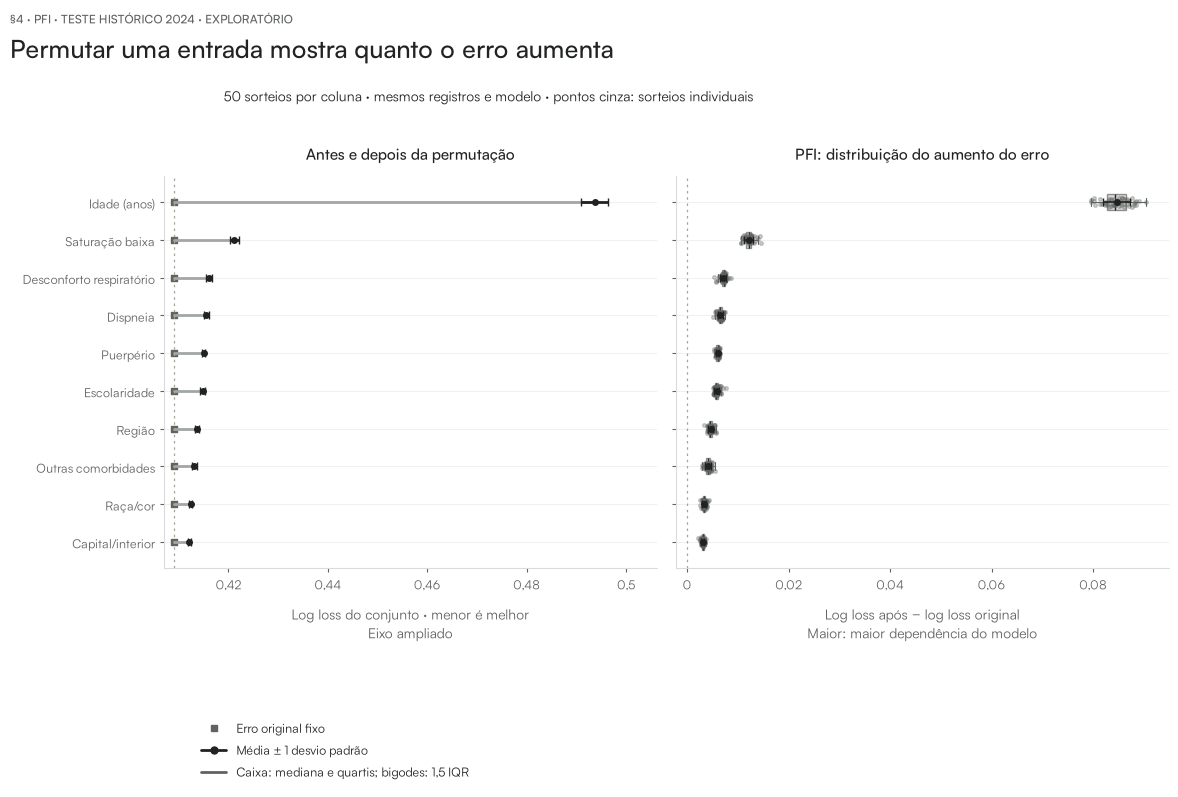

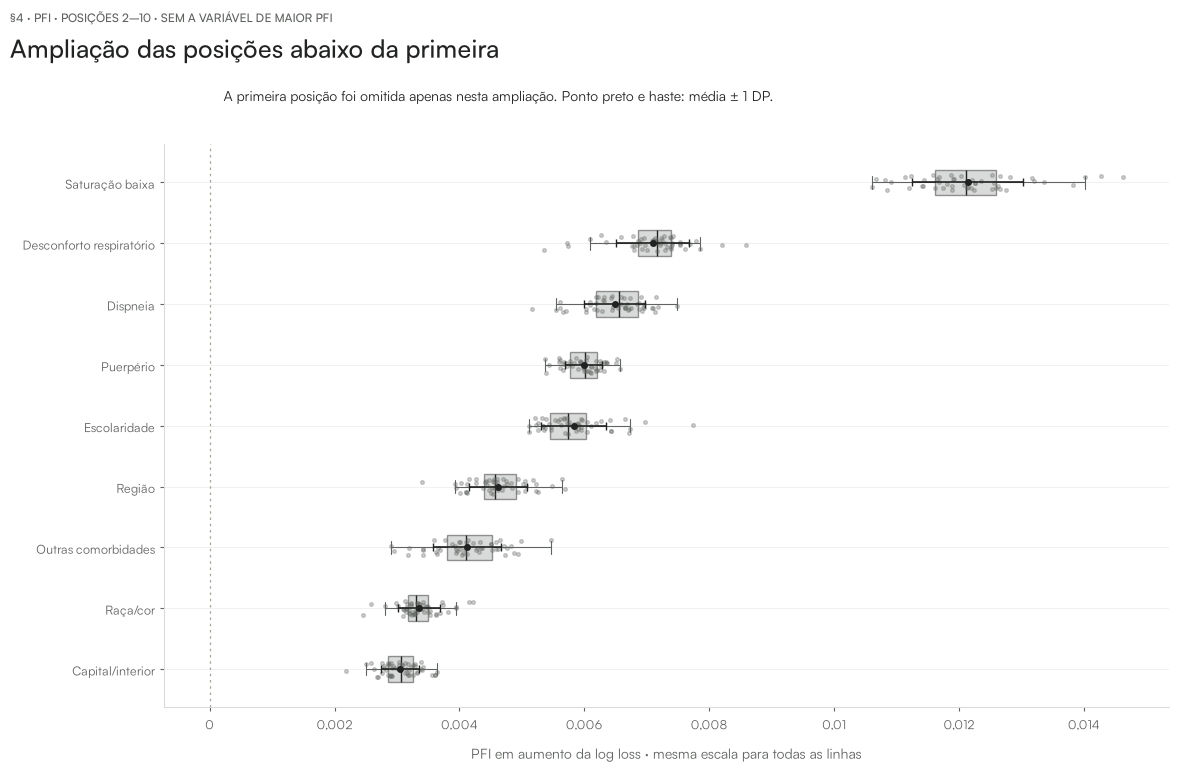

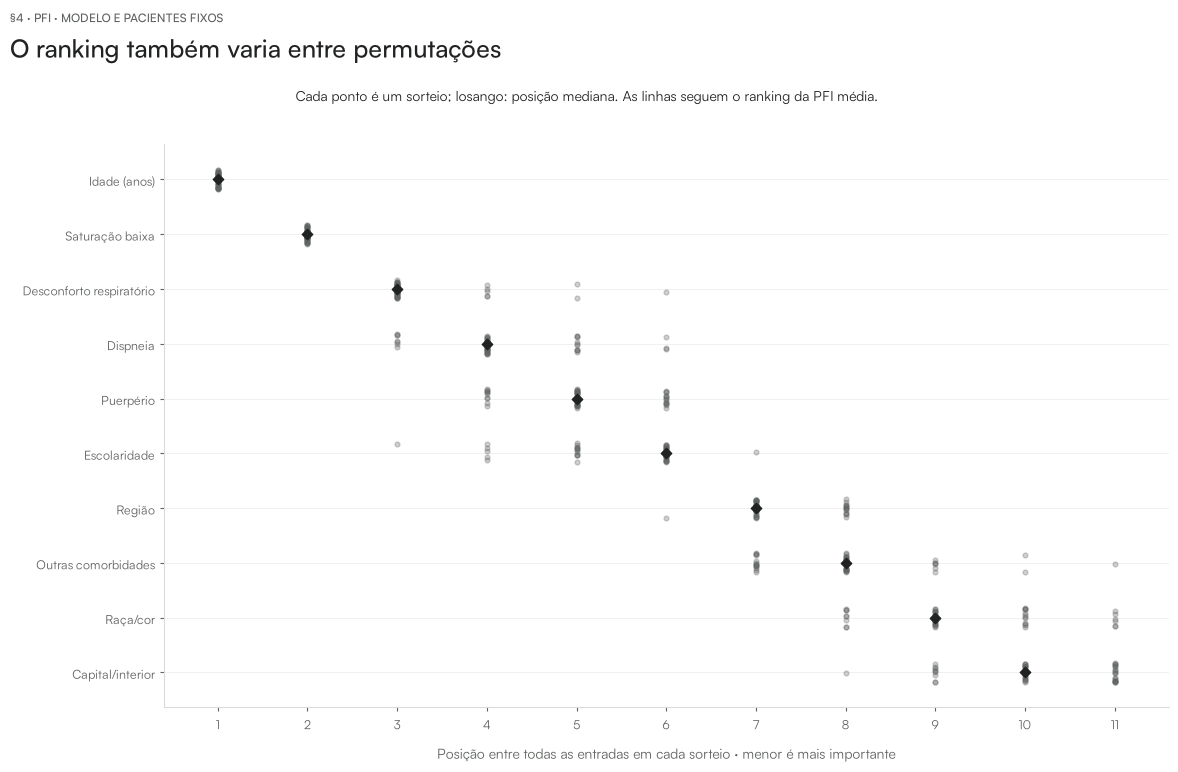

Equação da perda e figuras regeneradas com a mesma projeção de log loss dos slides.


In [8]:
for row in RECORD["rows"]:
    for metric, values in row["metrics"].items():
        after = np.asarray(values["after"], dtype=np.float64)
        sign = -1 if metric == "auc" else 1
        delta = sign * (after - RECORD["original"][metric])
        np.testing.assert_allclose(delta, values["delta"], rtol=0, atol=1e-15)
        np.testing.assert_allclose(delta.mean(), values["mean"], rtol=0, atol=1e-15)
        np.testing.assert_allclose(delta.std(ddof=1), values["sd"], rtol=0, atol=1e-15)
print("Entradas conferidas:", SP.pt_int(len(RECORD["rows"])))
print("Métricas conferidas:", SP.pt_int(len(RECORD["original"])))
print("Repetições em cada vetor:", SP.pt_int(protocol["repeats"]))
top10 = sorted(RECORD["rows"], key=lambda r: r["metrics"]["logloss"]["rank"])[:10]
print(SP.tabela(pd.DataFrame([{
    "entrada": r["label"],
    "Log loss original": RECORD["original"]["logloss"],
    "Log loss após médio": r["metrics"]["logloss"]["after_mean"],
    "aumento médio": r["metrics"]["logloss"]["mean"],
    "SD": r["metrics"]["logloss"]["sd"],
    "MCSE da média": r["metrics"]["logloss"]["mcse"],
    "posição média entre sorteios": r["metrics"]["logloss"]["rank_mean"],
    "SD da posição": r["metrics"]["logloss"]["rank_sd"],
} for r in top10]), casas=8))
F.render_slide_figures(PUBLIC, WORK / "figures_generated")
for fig in F.render_research_figures(RECORD, WORK / "figures_generated"):
    display(fig)
    plt.close(fig)
print("Equação da perda e figuras regeneradas com a mesma projeção de log loss dos slides.")


**O que olhar.** Idade lidera a média neste teste. Posições próximas podem trocar
 entre sorteios. Bigodes de boxplot não são os mesmos objetos que média ± SD.
 As figuras são regeneradas em diretório temporário; a promoção para o módulo é
 uma cópia explícita, não uma gravação silenciosa na aula.

## §5 — Diferença e razão

Com erro menor sendo melhor, Molnar permite ler a diferença
$FI_j^{diff}=E_{perm,j}-E_{orig}$ ou a razão
$FI_j^{ratio}=E_{perm,j}/E_{orig}$. A razão exige denominador positivo.
Seu ponto neutro é um, mas ela pode ficar abaixo de um se o erro diminuir após
 a permutação. A diferença correspondente será negativa.

Para estas métricas de perda com a mesma referência positiva, dividir por uma
 constante preserva a ordem das médias. Uma barra visual com outro eixo não muda
 o experimento. A razão não é porcentagem de óbitos identificados.

In [9]:
reference = RECORD["original"]["logloss"]
assert reference > 0
scale_rows = []
for row in top10:
    after = np.asarray(row["metrics"]["logloss"]["after"], dtype=np.float64)
    delta, ratio = after - reference, after / reference
    scale_rows.append({
        "entrada": row["label"], "diferença média": delta.mean(),
        "SD diferença": delta.std(ddof=1), "razão média": ratio.mean(),
        "SD razão": ratio.std(ddof=1),
    })
scales = pd.DataFrame(scale_rows)
np.testing.assert_array_equal(np.argsort(-scales["diferença média"]),
                              np.argsort(-scales["razão média"]))
for plot_row in PUBLIC["rows"]:
    record = next(r for r in RECORD["rows"] if r["feature"] == plot_row["feature"])
    after = np.asarray(record["metrics"]["logloss"]["after"])
    np.testing.assert_allclose(plot_row["difference_mean"], (after-reference).mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(plot_row["ratio_sd"], (after/reference).std(ddof=1), rtol=0, atol=1e-15)
print(SP.tabela(scales, casas=8))
print("Diferença neutra:", SP.pt(0, 0), "; razão neutra:", SP.pt(1, 0))
print("Ranking das médias preservado entre as escalas:", True)
print("Equações mostradas na apresentação:", PUBLIC["equations"])
print("Valores exportados para os gráficos coincidem com o registro antes do arredondamento:", True)

                 entrada diferença média SD diferença razão média   SD razão
            Idade (anos)      0,08463367   0,00265889  1,20691838 0,00650063
         Saturação baixa      0,01214364   0,00088863  1,02968962 0,00217259
Desconforto respiratório      0,00709591   0,00058119  1,01734857 0,00142093
                Dispneia      0,00648687   0,00048814  1,01585955 0,00119343
               Puerpério      0,00598886   0,00029667  1,01464199 0,00072533
            Escolaridade      0,00583024   0,00052389  1,01425418 0,00128084
                  Região      0,00461633   0,00046098  1,01128632 0,00112703
     Outras comorbidades      0,00412377   0,00054691  1,01008209 0,00133714
                Raça/cor      0,00335116   0,00033557  1,00819316 0,00082042
        Capital/interior      0,00304940   0,00030390  1,00745539 0,00074300
Diferença neutra: 0 ; razão neutra: 1
Ranking das médias preservado entre as escalas: True
Equações mostradas na apresentação: {'difference': '$FI_j = e_

**O que olhar.** Uma diferença pequena pode representar uma mudança relativa
relevante quando o erro original é pequeno. A unidade deve aparecer no eixo.
 O aumento da perda não mostra se uma feature eleva ou reduz a probabilidade de
 um paciente: PFI não é um gráfico de direção de efeito.

## §6 — Dependência: mover o par ou embaralhar dentro do grupo

O exemplo compara cardiopatia e diabetes no mesmo teste e preditor. Primeiro
 repetimos a operação marginal separadamente. No diagnóstico conjunto, ambos os
valores vêm da **mesma linha doadora**, preservando o par observado.

Na opção por subgrupos de Molnar, diabetes define os grupos e fica fixa:
cardiopatia só recebe um valor de uma linha com a mesma categoria de diabetes.
A ordem global uniforme é filtrada por grupo. Avaliamos cada grupo com o próprio
erro original e, adicionalmente, calculamos a média ponderada pelos tamanhos dos
 grupos. Isso condiciona em diabetes; não em todas as outras features.

A comparação é exploratória. Um valor conjunto maior do que a soma dos valores
individuais não comprova interação, causalidade ou redundância.

In [10]:
pair = ("cardiopati", "diabetes")
def pair_counts(frame):
    return frame.groupby(list(pair), observed=False).size().sort_index()

original_pairs = pair_counts(xe)
diabetes_values = xe["diabetes"].to_numpy()
levels = list(xe["diabetes"].cat.categories)
restricted_orders = []
for order in orders:
    donor = np.arange(len(xe))
    for level in levels:
        receivers = np.flatnonzero(diabetes_values == level)
        donors = order[diabetes_values[order] == level]
        donor[receivers] = donors
    np.testing.assert_array_equal(diabetes_values[donor], diabetes_values)
    restricted_orders.append(donor)

actual_diagnostics = {}
for key, columns, selected_orders in [
    ("cardiopati", "cardiopati", orders),
    ("diabetes", "diabetes", orders),
    ("joint", pair, orders),
    ("within", "cardiopati", restricted_orders),
]:
    before, after = K.trace_pfi(model, xe, ye, columns, selected_orders, log_loss)
    stored = next(r for r in PUBLIC["dependence"]["results"] if r["key"] == key)
    discrepancy = float(np.max(np.abs(after - np.asarray(stored["after"]))))
    assert discrepancy < 5e-5
    actual_diagnostics[key] = after
    print(key, "; média do aumento:", SP.pt((after - before).mean(), 8),
          "; SD amostral:", SP.pt(after.std(ddof=1), 8),
          "; maior desvio do registro:", SP.pt_sig(discrepancy))

weighted_after = []
for order, donor in zip(orders, restricted_orders):
    joint = K.permutar_colunas(xe, pair, order)
    within = K.permutar_colunas(xe, "cardiopati", donor)
    pd.testing.assert_series_equal(pair_counts(joint), original_pairs)
    pd.testing.assert_series_equal(pair_counts(within), original_pairs)
    pd.testing.assert_series_equal(within["diabetes"], xe["diabetes"])
    p_within = np.asarray(model.predict_proba(within)[:, 1], dtype=np.float64)
    weighted_after.append(sum(
        np.mean(H.individual_logloss(ye[diabetes_values == level], p_within[diabetes_values == level]))
        * np.sum(diabetes_values == level) / len(ye)
        for level in levels if np.any(diabetes_values == level)
    ))
np.testing.assert_allclose(weighted_after, actual_diagnostics["within"], atol=1e-15, rtol=0)
print("Pares preservados em todas as permutações conjuntas e restritas:", True)
print("Erro ponderado dos subgrupos coincide com erro completo em todas as repetições:", True)
print("Resultados agregados que alimentam a apresentação:")
diagnostic_table = pd.DataFrame([{
    "operação": r["label"], "Log loss original": r["before"],
    "Log loss após médio": r["after_mean"],
    "aumento médio": r["difference_mean"], "SD": r["difference_sd"],
    "aumento × 1000": r["difference_mean"] * 1000,
    "SD × 1000": r["difference_sd"] * 1000,
} for r in PUBLIC["dependence"]["results"]])
print(SP.tabela(diagnostic_table, casas=8))
print("Fator visual do gráfico:", SP.pt_int(1000))
pd.testing.assert_frame_equal(xe, original_x)
np.testing.assert_array_equal(ye, original_y)
assert bytes(model.get_booster().save_raw()) == model_snapshot
print("Modelo, matriz e alvos originais continuam preservados:", True)

cardiopati ; média do aumento: 0,00183720 ; SD amostral: 0,00015314 ; maior desvio do registro: 0,00


diabetes ; média do aumento: 0,00131653 ; SD amostral: 0,00018326 ; maior desvio do registro: 0,00


joint ; média do aumento: 0,00362043 ; SD amostral: 0,00027092 ; maior desvio do registro: 0,00


within ; média do aumento: 0,00055542 ; SD amostral: 0,00015299 ; maior desvio do registro: 0,00


Pares preservados em todas as permutações conjuntas e restritas: True
Erro ponderado dos subgrupos coincide com erro completo em todas as repetições: True
Resultados agregados que alimentam a apresentação:
                     operação Log loss original Log loss após médio aumento médio         SD aumento × 1000  SD × 1000
          Heart disease alone        0,40901958          0,41085678    0,00183720 0,00015314     1,83720119 0,15313910
               Diabetes alone        0,40901958          0,41033611    0,00131653 0,00018326     1,31653016 0,18325631
                Both together        0,40901958          0,41264000    0,00362043 0,00027092     3,62042874 0,27091717
Heart disease within diabetes        0,40901958          0,40957500    0,00055542 0,00015299     0,55542161 0,15298505
Fator visual do gráfico: 1.000


Modelo, matriz e alvos originais continuam preservados: True


**O que olhar.** Mover o par preserva sua distribuição conjunta, mas pode romper
relações com outras entradas. Restringir o embaralhamento a subgrupos preserva a
categoria de diabetes de cada receptor. As duas operações mudam a pergunta.

## §7 — O que o livro diz e o que esta aula estabelece

Molnar descreve a PFI como deterioração do desempenho de um modelo fixo após
permutar uma entrada. O capítulo destaca dependência, extrapolação, importância
condicional e o caminho por subgrupos. Nesta aula seguimos o procedimento por
subgrupos para diabetes; a permutação conjunta é um diagnóstico complementar.

O registro completo evita chamar um exemplo isolado de importância média. A
 referência fixa explica o SD original nulo entre sorteios; isso não elimina
incerteza na população, no ajuste ou no transporte temporal. A quantidade de
repetições é uma escolha de protocolo, não uma demonstração de convergência.

A log loss responde à qualidade das probabilidades. AUC e outros escores podem
produzir ordens diferentes. A migração foi decidida por aderência ao exemplo de classificação de Molnar,
após comparar as réguas no mesmo experimento. Não selecionamos novos sorteios,
fichas ou modelos para obter um ranking mais favorável.

In [11]:
# A saída distribuível é sempre uma projeção explícita, nunca o JSON inteiro.
Q.validate_aggregates(PUBLIC)
exported = WORK / "figures_generated/pfi-aggregates.json"
exported.write_text(json.dumps(PUBLIC, ensure_ascii=False, indent=2) + "\n")
print("Apresentação usa resultados agregados do teste completo e uma demonstração real separada com ordem sorteada.")
print("Ranking completo veio do registro; os traços de idade, saturação e dependência foram recalculados.")
print("Exportação agregada validada, sem preview de pacientes:", "preview" not in PUBLIC)
print("Arquivos gerados fora da árvore versionada:", not WORK.is_relative_to(REPO))
(WORK / "figures_generated/pfi_presentation_logloss.json").write_text(json.dumps(PUBLIC, ensure_ascii=False, indent=2) + "\n")
print("Métrica principal explicitada na projeção:", PUBLIC["protocol"]["primary_metric"])


Apresentação usa resultados agregados do teste completo e uma demonstração real separada com ordem sorteada.
Ranking completo veio do registro; os traços de idade, saturação e dependência foram recalculados.
Exportação agregada validada, sem preview de pacientes: True
Arquivos gerados fora da árvore versionada: True
Métrica principal explicitada na projeção: logloss


## §8 — A mesma PFI vista por Brier, log loss, MAE e AUC

A pergunta da aula pode mudar sem alterar o preditor nem suas previsões. Recalculamos os resumos e os rankings a partir dos escores registrados em cada permutação, sem escolher novos pacientes ou ordens. Brier, log loss e MAE são perdas: maior após embaralhar significa pior desempenho. AUC é um escore de discriminação: menor após embaralhar significa pior desempenho. Orientamos todas as diferenças para que importância positiva signifique piora.

As grandezas têm escalas distintas. Comparamos posições e a mensagem preditiva, sem equiparar o tamanho bruto de uma diferença de Brier a uma de log loss ou AUC. A dispersão continua sendo a dos embaralhamentos, condicionada ao modelo e ao conjunto avaliados.

MAE é calculado nas probabilidades contínuas de óbito, contra o desfecho binário. Não aplicamos um limiar antes dessa conta. Ele é uma distância calculável, mas a perda absoluta incentiva a mediana do desfecho, não a probabilidade verdadeira. Brier e log loss são adequadas à avaliação probabilística em média, conforme a [documentação de escores](https://scikit-learn.org/stable/modules/model_evaluation.html#which-scoring-function-should-i-use).


Todos os escores históricos conferidos ao reproduzir as mesmas previsões; maior discrepância: 0,00
Modelo, teste e ordens de permutação: os mesmos do experimento registrado.
Registros: 16.142 ; óbitos: 2.945
Entradas: 40 ; repetições por entrada: 50
Brier/log loss/MAE: diferença = após - original; AUC: diferença = original - após.
SD amostral entre permutações; modelo e registros fixos, sem reamostragem.
 métrica         entrada   original primeira após média após diferença orientada         SD posição repetições piores razão perdas aumento relativo %
   Brier    Idade (anos) 0,13080778    0,15357206 0,15425722          0,02344944 0,00073672       1                50   1,17926637        17,92663726
   Brier Saturação baixa 0,13080778    0,13485074 0,13509785          0,00429007 0,00032827       2                50   1,03279675         3,27967477
Log loss    Idade (anos) 0,40901958    0,49139918 0,49365325          0,08463367 0,00265889       1                50   1,20691838        20,6

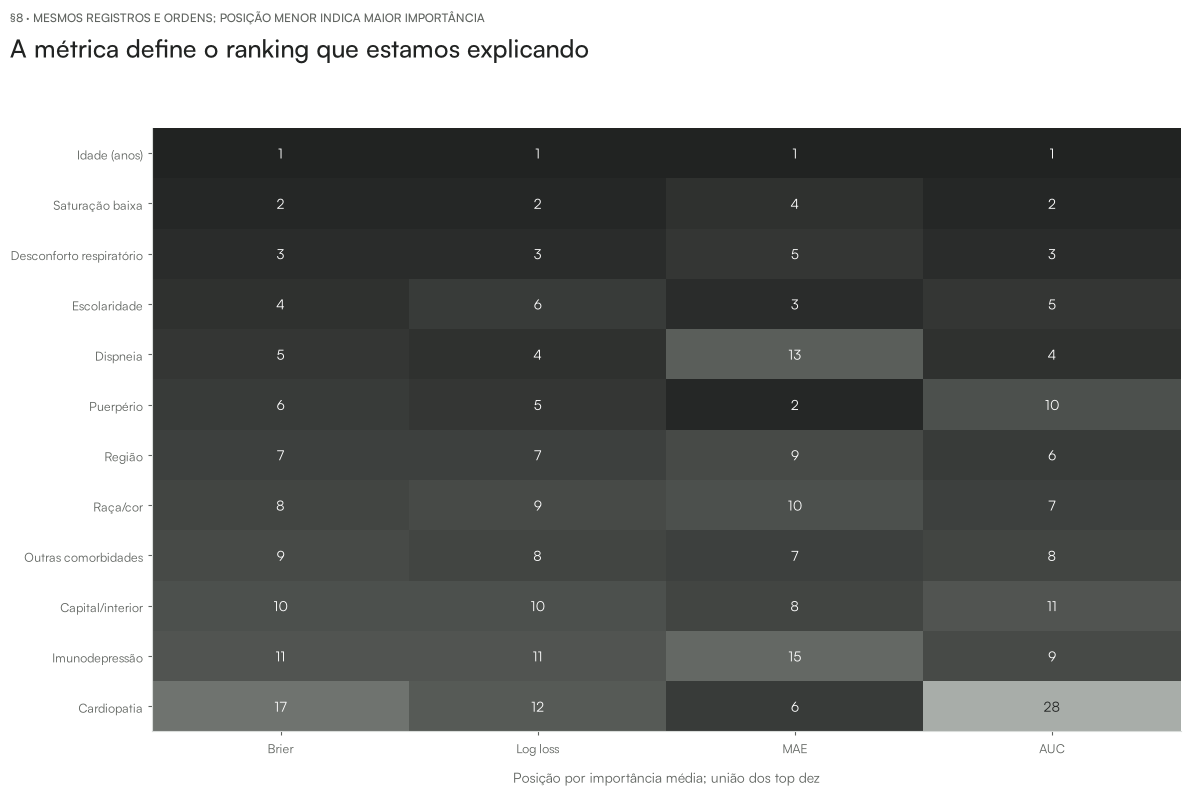

figura: figures_generated/metricas-idade-saturacao.png


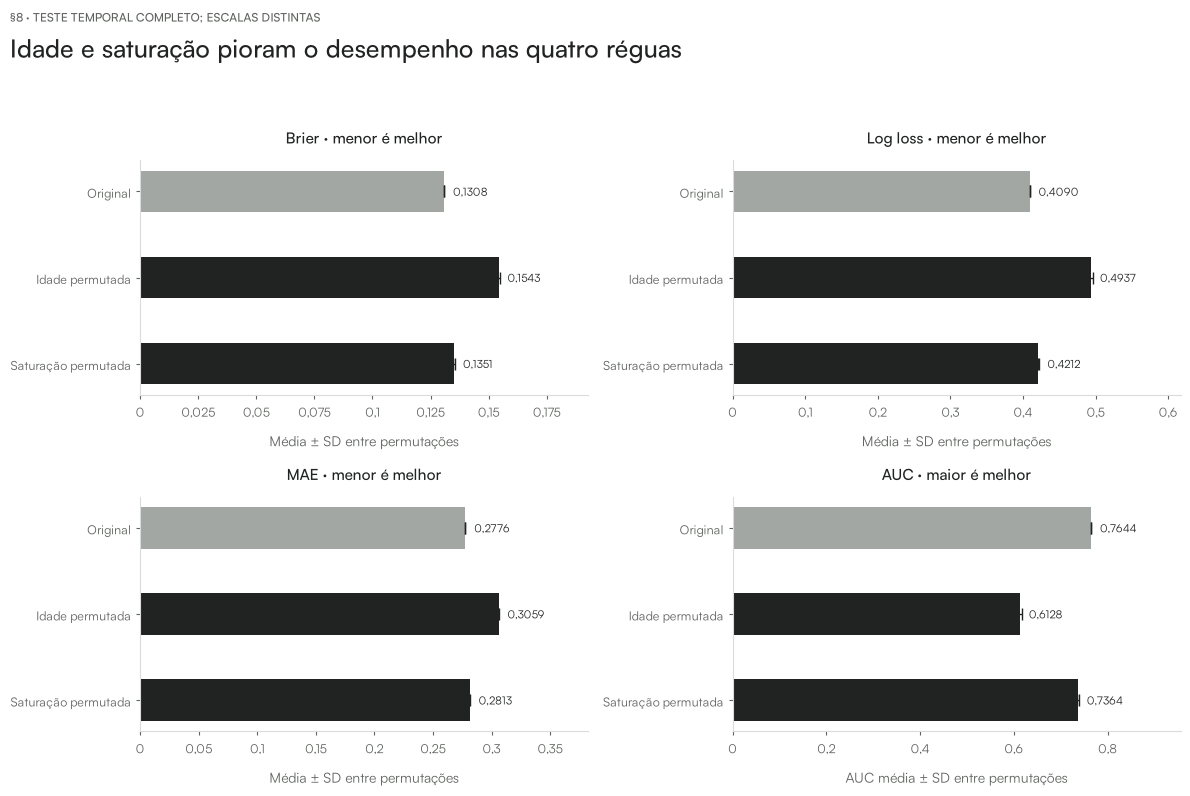

In [12]:
import srag_74_metric_comparison as MC
# Recreate the registered predictions only to measure the previously absent MAE.
mae_baseline = float(mean_absolute_error(ye, p_original))
np.testing.assert_allclose(mae_baseline, np.mean(np.abs(ye-p_original)), rtol=0, atol=1e-15)
mae_after = {}
maximum_score_discrepancy = 0.
for row in RECORD["rows"]:
    values=[]
    for repeat, donor in enumerate(orders):
        changed=K.permutar_colunas(xe, row["feature"], donor)
        prediction=np.asarray(model.predict_proba(changed)[:,1],dtype=np.float64)
        values.append(float(mean_absolute_error(ye,prediction)))
        for metric,score in P.scores(ye,prediction).items():
            discrepancy=abs(score-row["metrics"][metric]["after"][repeat])
            maximum_score_discrepancy=max(maximum_score_discrepancy,discrepancy)
    mae_after[row["feature"]]=values
assert maximum_score_discrepancy<5e-5
metric_record=MC.add_mae(RECORD,mae_baseline,mae_after)
comparison = MC.compare_record(metric_record)
comparison["mae_definition"]="mean(abs(y_observed - p_death)); no decision threshold"
comparison["mae_prediction_audit_maximum"] = maximum_score_discrepancy
print("Todos os escores históricos conferidos ao reproduzir as mesmas previsões; maior discrepância:", SP.pt_sig(maximum_score_discrepancy))

by_feature = {row["feature"]: row for row in comparison["features"]}
print("Modelo, teste e ordens de permutação: os mesmos do experimento registrado.")
print("Registros:", SP.pt_int(protocol["n_evaluation"]), "; óbitos:", SP.pt_int(protocol["events"]))
print("Entradas:", SP.pt_int(len(by_feature)), "; repetições por entrada:", SP.pt_int(protocol["repeats"]))
print("Brier/log loss/MAE: diferença = após - original; AUC: diferença = original - após.")
print("SD amostral entre permutações; modelo e registros fixos, sem reamostragem.")
summary_table = pd.DataFrame([{
    "métrica": MC.LABELS[metric], "entrada": by_feature[feature]["label"],
    "original": values["before"], "primeira após": values["first_after"],
    "média após": values["after_mean"], "diferença orientada": values["importance_mean"],
    "SD": values["importance_sd"], "posição": values["rank"],
    "repetições piores": values["worse_repeats"],
    "razão perdas": values.get("ratio_of_means", np.nan),
    "aumento relativo %": values.get("relative_increase_percent", np.nan),
} for metric in MC.METRICS for feature in ("idade_anos", "saturacao")
for values in [by_feature[feature]["metrics"][metric]]])
print(SP.tabela(summary_table, casas=8))
rank_table = pd.DataFrame([{
    "entrada": row["label"], **{MC.LABELS[m]: row["metrics"][m]["rank"] for m in MC.METRICS}
} for row in sorted(comparison["features"], key=lambda row: row["metrics"]["brier"]["rank"])])
print("Ranking completo calculado pela diferença média orientada:")
print(SP.tabela(rank_table, casas=0))
print("Concordância dos rankings nas entradas completas:")
print(SP.tabela(pd.DataFrame(comparison["agreement"])[["left", "right", "spearman", "top10_common"]], casas=8))
for feature in ("idade_anos", "saturacao", "capital_interior", "imunodepre"):
    row = by_feature[feature]
    print(row["label"], "; presença no top dez:", "; ".join(
        f'{MC.LABELS[m]} {SP.pt_int(row["metrics"][m]["top10_repeats"])}/{SP.pt_int(protocol["repeats"])}'
        for m in MC.METRICS))
for feature in ("idade_anos", "saturacao"):
    for metric in MC.METRICS:
        values = by_feature[feature]["metrics"][metric]
        assert values["worse_repeats"] == protocol["repeats"]
print("Idade e saturação: todas as permutações pioram cada escore avaliado.")
print("Doses antes dos sintomas: perguntas diferentes nas mesmas previsões.")
print(SP.tabela(pd.DataFrame([{
    "métrica": MC.LABELS[m], **{k: by_feature["n_doses_antes_do_sintoma"]["metrics"][m][k]
    for k in ("before", "after_mean", "importance_mean", "importance_sd", "rank", "worse_repeats", "better_repeats")}
} for m in MC.METRICS]), casas=8))

fig, ax = plt.subplots(figsize=SP.PAINEL)
selected = [row for row in sorted(comparison["features"], key=lambda row: row["metrics"]["brier"]["rank"])
            if any(row["metrics"][m]["rank"]<=10 for m in MC.METRICS)]
rank_values=np.asarray([[row["metrics"][m]["rank"] for m in MC.METRICS] for row in selected])
rank_image = ax.imshow(rank_values, cmap=SP.CMAP_INTENSIDADE.reversed(),
                       vmin=1, vmax=40, aspect="auto")
for i,row in enumerate(rank_values):
    for j,value in enumerate(row):
        rgb = np.asarray(rank_image.cmap(rank_image.norm(value))[:3])
        linear_rgb = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4)
        luminance = float(linear_rgb @ np.asarray([.2126, .7152, .0722]))
        label_color = SP.PAPEL if luminance < .21 else SP.ESCURO
        ax.text(j, i, SP.pt_int(value), ha="center", va="center", color=label_color)
ax.set_xticks(range(len(MC.METRICS)),[MC.LABELS[m] for m in MC.METRICS])
ax.set_yticks(range(len(selected)),[row["label"] for row in selected])
ax.set_xlabel("Posição por importância média; união dos top dez")
ax.grid(visible=False)
SP.titulo(fig,"A métrica define o ranking que estamos explicando","§8 · mesmos registros e ordens; posição menor indica maior importância")
SP.salvar(fig,"metricas-ranking",ticks_pt=False)
display(fig)
plt.close(fig)

fig, axes_grid = plt.subplots(2,2, figsize=SP.PAINEL)
axes=axes_grid.ravel()
for ax, metric in zip(axes, MC.METRICS):
    values = [comparison["original"][metric]] + [by_feature[f]["metrics"][metric]["after_mean"] for f in ("idade_anos", "saturacao")]
    deviations = [0.] + [by_feature[f]["metrics"][metric]["after_sd"] for f in ("idade_anos", "saturacao")]
    ax.barh([2,1,0], values, color=[SP.CINZA_CLARO,SP.ESCURO,SP.ESCURO], height=.48)
    ax.errorbar(values, [2,1,0], xerr=deviations, fmt="none", ecolor=SP.ESCURO, capsize=4, linewidth=1)
    for y, value in zip([2,1,0],values):
        ax.text(value+max(values)*.025,y,SP.pt(value,4),va="center",fontsize=8)
    ax.set_yticks([2,1,0],["Original", "Idade permutada", "Saturação permutada"])
    ax.set_xlim(0,max(values)*1.25)
    ax.set_title(MC.LABELS[metric]+(" · menor é melhor" if metric!="auc" else " · maior é melhor"))
    ax.set_xlabel("Média ± SD entre permutações" if metric!="auc" else "AUC média ± SD entre permutações")
    ax.grid(axis="y",visible=False)
SP.titulo(fig,"Idade e saturação pioram o desempenho nas quatro réguas", "§8 · teste temporal completo; escalas distintas")
SP.salvar(fig,"metricas-idade-saturacao")
display(fig)
plt.close(fig)


**O que olhar.** O gráfico de posições compara a mesma variável entre as réguas. O gráfico antes/depois mostra o escore original e a média das permutações, com seu desvio padrão, em eixos próprios. A troca da métrica não mudou probabilidades nem decisões de classe.

### Conferir também o exemplo final de dependência

A importância conjunta e a permutação dentro dos estados de diabetes respondem a perguntas diferentes. Reavaliamos essas mesmas operações com as perdas e com AUC antes de recomendar a migração da aula. Não chamamos a diferença conjunta de efeito causal ou interação isolada.


Exemplo final: mesmas operações e mesmas ordens; mudamos apenas o escore.
                     operação  métrica diferença orientada         SD média após
                  Cardiopatia    Brier          0,00036655 0,00005026 0,13117433
                  Cardiopatia Log loss          0,00183720 0,00015314 0,41085678
                  Cardiopatia      MAE          0,00315709 0,00007992 0,28072567
                  Cardiopatia      AUC          0,00028524 0,00027183 0,76416315
                     Diabetes    Brier          0,00042273 0,00007109 0,13123051
                     Diabetes Log loss          0,00131653 0,00018326 0,41033611
                     Diabetes      MAE          0,00152861 0,00008931 0,27909718
                     Diabetes      AUC          0,00147567 0,00036641 0,76297272
                Both together    Brier          0,00093953 0,00009813 0,13174731
                Both together Log loss          0,00362043 0,00027092 0,41264000
                Both together      

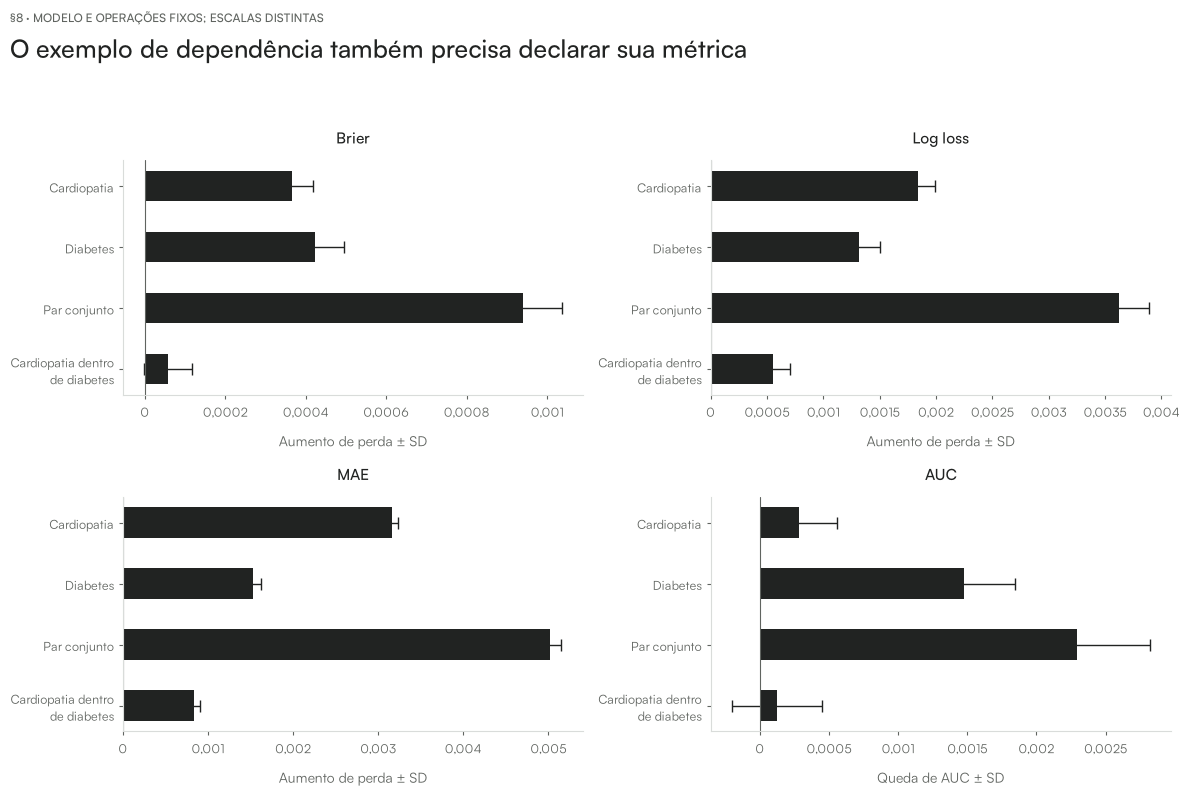

Primeira permutação global: escores conferidos com nova previsão nas quatro métricas.


Modelo, fichas e alvos preservados durante toda a comparação: True
Janela didática: médias destas fichas, sem generalização para o teste.
    estado      brier    logloss        auc        mae
  Original 0,31962453 0,89476575 0,50000000 0,49087721
       Age 0,31170574 0,87046091 0,56250000 0,47365226
Low oxygen 0,30386299 0,85034903 0,56250000 0,47413485
A animação continua usando a média do teste completo em todas as permutações.
MAE: probabilidades contínuas versus diagnósticos (não são novos modelos selecionados).
   entrada avaliada        MAE
model_probabilities 0,27756858
        always_zero 0,18244332
  always_prevalence 0,29831550
thresholded_classes 0,18083261
Sempre probabilidade zero tem MAE menor que o modelo; isso expõe a limitação da régua, não superioridade clínica.
Exemplo sintético, não dados SRAG: risco conhecido, perdas médias esperadas.
probabilidade verdadeira sintética previsão avaliada MAE esperado Brier esperado log loss esperada
                        0,20000

In [13]:
# Recompute the end-of-lecture dependence example, preserving its exact orders.
# Individual marginal traces already have all scores in the original record.
dependence_metrics = []
for key, columns, selected_orders in [("joint", pair, orders), ("within", "cardiopati", restricted_orders)]:
    measured = {m: [] for m in MC.METRICS}
    for donor in selected_orders:
        changed = K.permutar_colunas(xe, columns, donor)
        prediction = np.asarray(model.predict_proba(changed)[:,1], dtype=np.float64)
        scored=P.scores(ye,prediction)
        scored["mae"]=float(mean_absolute_error(ye,prediction))
        for metric, score in scored.items():
            measured[metric].append(score)
    np.testing.assert_allclose(measured["logloss"], actual_diagnostics[key], rtol=0,atol=1e-15)
    label = next(r["label"] for r in PUBLIC["dependence"]["results"] if r["key"]==key)
    dependence_metrics.append({"key":key,"label":label,"metrics":{
        m: MC.summarise_values(measured[m], comparison["original"][m], m) for m in MC.METRICS}})
for feature in ("cardiopati", "diabetes"):
    row=by_feature[feature]
    dependence_metrics.append({"key":feature,"label":row["label"],"metrics":row["metrics"]})
dependence_metrics.sort(key=lambda row:["cardiopati","diabetes","joint","within"].index(row["key"]))
comparison["dependence"] = dependence_metrics
print("Exemplo final: mesmas operações e mesmas ordens; mudamos apenas o escore.")
print(SP.tabela(pd.DataFrame([{"operação":row["label"],"métrica":MC.LABELS[m],
    "diferença orientada":row["metrics"][m]["importance_mean"],"SD":row["metrics"][m]["importance_sd"],
    "média após":row["metrics"][m]["after_mean"]}
    for row in dependence_metrics for m in MC.METRICS]),casas=8))

fig,axes_grid=plt.subplots(2,2,figsize=SP.PAINEL)
axes=axes_grid.ravel()
for ax,metric in zip(axes,MC.METRICS):
    means=[row["metrics"][metric]["importance_mean"] for row in dependence_metrics]
    deviations=[row["metrics"][metric]["importance_sd"] for row in dependence_metrics]
    ax.barh(range(4),means,color=SP.ESCURO,height=.5)
    ax.errorbar(means,range(4),xerr=deviations,fmt="none",ecolor=SP.ESCURO,capsize=4,linewidth=1)
    ax.axvline(0,color=SP.CINZA,linewidth=.8)
    ax.set_yticks(range(4),["Cardiopatia","Diabetes","Par conjunto","Cardiopatia dentro\nde diabetes"])
    ax.invert_yaxis()
    ax.set_title(MC.LABELS[metric])
    ax.set_xlabel("Aumento de perda ± SD" if metric!="auc" else "Queda de AUC ± SD")
    ax.grid(axis="y",visible=False)
SP.titulo(fig,"O exemplo de dependência também precisa declarar sua métrica","§8 · modelo e operações fixos; escalas distintas")
SP.salvar(fig,"metricas-dependencia")
display(fig)
plt.close(fig)

# Check a real full-test prediction for each displayed single-column round.
for feature in ("idade_anos","saturacao"):
    changed=K.permutar_colunas(xe,feature,orders[0])
    predicted=np.asarray(model.predict_proba(changed)[:,1],dtype=np.float64)
    scores=P.scores(ye,predicted)
    scores["mae"]=float(mean_absolute_error(ye,predicted))
    for metric in MC.METRICS:
        np.testing.assert_allclose(scores[metric],by_feature[feature]["metrics"][metric]["first_after"],rtol=0,atol=5e-5)
print("Primeira permutação global: escores conferidos com nova previsão nas quatro métricas.")
pd.testing.assert_frame_equal(xe,original_x)
np.testing.assert_array_equal(ye,original_y)
assert bytes(model.get_booster().save_raw())==model_snapshot
print("Modelo, fichas e alvos preservados durante toda a comparação:", True)

# The eight visible receivers are a teaching window, never a PFI estimate.
window_metrics=[]
for label,probability in [("Original",case_p_original)]+[(r["label"],case_table["p_after_"+r["cell"]].to_numpy()) for r in case_rounds]:
    measured=P.scores(case_y,probability)
    measured["mae"]=float(mean_absolute_error(case_y,probability))
    window_metrics.append({"estado":label,**measured})
comparison["teaching_window_scores"]=window_metrics
print("Janela didática: médias destas fichas, sem generalização para o teste.")
print(SP.tabela(pd.DataFrame(window_metrics),casas=8))
print("A animação continua usando a média do teste completo em todas as permutações.")

# Diagnostic comparators illustrate why MAE of probabilities is not proper.
prevalence=float(np.mean(ye))
mae_comparators={"model_probabilities":mae_baseline,
    "always_zero":float(mean_absolute_error(ye,np.zeros(len(ye)))),
    "always_prevalence":float(mean_absolute_error(ye,np.full(len(ye),prevalence))),
    "thresholded_classes":float(mean_absolute_error(ye,(p_original>=case_threshold).astype(int)))}
np.testing.assert_allclose(mae_comparators["always_zero"],prevalence,rtol=0,atol=0)
np.testing.assert_allclose(mae_comparators["thresholded_classes"],np.mean((p_original>=case_threshold)!=ye),rtol=0,atol=0)
comparison["mae_comparators"]=mae_comparators
print("MAE: probabilidades contínuas versus diagnósticos (não são novos modelos selecionados).")
print(SP.tabela(pd.DataFrame([{"entrada avaliada":key,"MAE":value} for key,value in mae_comparators.items()]),casas=8))
print("Sempre probabilidade zero tem MAE menor que o modelo; isso expõe a limitação da régua, não superioridade clínica.")
# A fully declared synthetic example: Bernoulli event risk is known here only.
q=.2
example=[]
for prediction in (.01,.2):
    example.append({"probabilidade verdadeira sintética":q,"previsão avaliada":prediction,
        "MAE esperado":q*(1-prediction)+(1-q)*prediction,
        "Brier esperado":q*(1-prediction)**2+(1-q)*prediction**2,
        "log loss esperada":-q*np.log(prediction)-(1-q)*np.log(1-prediction)})
comparison["mae_synthetic_example"]={"kind":"synthetic Bernoulli expectation; not SRAG records","rows":example}
print("Exemplo sintético, não dados SRAG: risco conhecido, perdas médias esperadas.")
print(SP.tabela(pd.DataFrame(example),casas=8))
assert example[0]["MAE esperado"]<example[1]["MAE esperado"]
assert example[0]["Brier esperado"]>example[1]["Brier esperado"]
assert example[0]["log loss esperada"]>example[1]["log loss esperada"]

metric_output=WORK/"figures_generated/pfi_metric_comparison.json"
metric_output.write_text(json.dumps(comparison,ensure_ascii=False,indent=2,allow_nan=False)+"\n")
print("A evidência agregada completa foi gerada fora da árvore versionada.")


**O que olhar.** AUC avalia ordenação entre registros com desfechos distintos e não fornece uma perda por ficha. Log loss conserva a narrativa da probabilidade atribuída ao desfecho ocorrido, seguida da média. Para a aula seguir o exemplo de classificação de Molnar, podemos escolher log loss por essa razão didática; não por deixar o ranking mais favorável. Curvas de calibração continuam necessárias para avaliar calibração especificamente.


## §9 — A distribuição ficou igual; por que o erro mudou?

Escolhemos as fichas **C e H**, já presentes na janela real da §3, depois de
inspecionar exemplos para tornar a explicação visível. Ambas têm cardiopatia
registrada como Não e desfechos distintos. Esta seleção é didática, não uma
amostra representativa nem uma ordem escolhida para estimar a PFI.

Trocamos apenas suas idades, mantendo o preditor, as outras entradas e os
respectivos desfechos. As fichas originais são reais; as combinações depois da
troca são entradas perturbadas do experimento, não novos pacientes observados.
As faixas etárias organizam a figura; o modelo continua recebendo a idade
contínua original. A troca conserva até o conjunto exato das idades, não apenas
os percentuais por faixa.

Comparamos a probabilidade atribuída ao desfecho que realmente ocorreu e sua
perda logarítmica. Este é um contraste entre estas fichas, **não a primeira
permutação registrada, a PFI global ou a PFI por subgrupos**. Não estimamos SD ou
incerteza com esta troca selecionada.


Demonstração selecionada após inspeção: fichas C, H ; não é PFI global.
Fichas: 2 ; entradas: 40 ; ano do teste: 2.024
Grupo fixo: cardiopatia = Não. Ordem da troca, base zero: [1, 0]
SHA256 da fonte: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
SHA256 da estrutura: d8cebf0e21f762aa8588bc1a819078d4e8071743f6e19207e6b0a64adf8523ac
Contrato de reconstrução e conferência das referências congeladas:
         estado max_ulp  max_abs budget_ulp
       Original       0 0,000000          8
Idades trocadas       0 0,000000          8
Fichas reais originais e entradas perturbadas; desfechos permanecem nas mesmas fichas:
ficha estado cardiopatia y_obito idade_anos  p_obito p_desfecho_ocorrido p_obito_percentual p_desfecho_percentual log_loss
    C before         Não       0  20,054756 0,024467            0,975533           2,446677             97,553323 0,024771
    C  after    

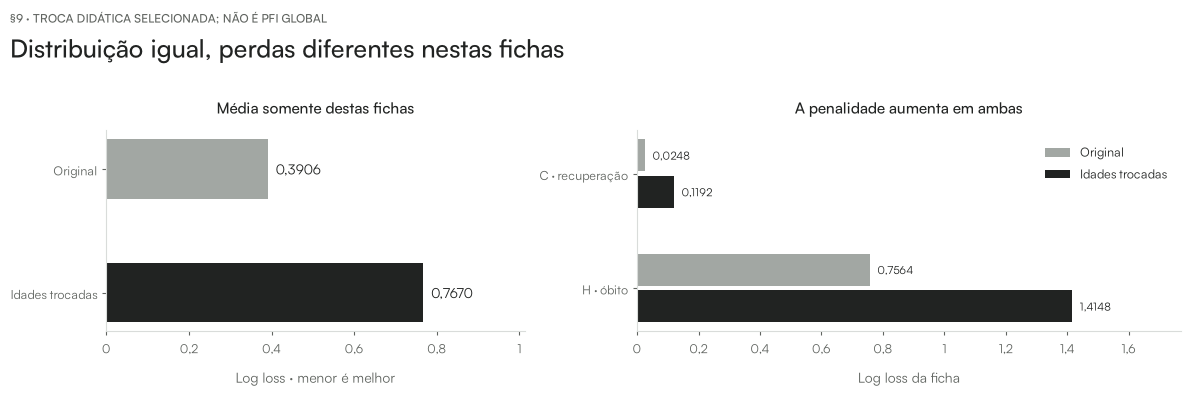

In [14]:
# Reutilizar fichas já exibidas, sem imprimir identificadores ou posições no Gold.
two_labels = ["C", "H"]
two_positions = [case_labels.index(label) for label in two_labels]
two_x = case_x.iloc[two_positions].reset_index(drop=True).copy(deep=True)
two_y = case_y[two_positions].copy()
two_x_snapshot, two_y_snapshot = two_x.copy(deep=True), two_y.copy()
two_model_snapshot = bytes(model.get_booster().save_raw(raw_format="ubj"))
assert H.structure_sha256(model) == H.REFERENCE_STRUCTURE_SHA256
assert two_x["cardiopati"].eq("nao").all()
assert list(two_x.columns) == list(M.FEATURES)
assert two_x.shape[1] == len(protocol["features"])
np.testing.assert_array_equal(two_y, [0, 1])

# A ordem é uma troca didática explícita; não é sorteio novo nem ordem global.
two_order = np.array([1, 0], dtype=int)
two_after_x = K.permutar_colunas(two_x, "idade_anos", two_order)
pd.testing.assert_frame_equal(two_after_x.drop(columns="idade_anos"),
                              two_x.drop(columns="idade_anos"))
assert two_after_x.dtypes.equals(two_x.dtypes)
np.testing.assert_array_equal(np.sort(two_after_x["idade_anos"].to_numpy()),
                              np.sort(two_x["idade_anos"].to_numpy()))

two_edges = np.array([0., 18., 40., 60., 80., np.inf])
two_bin_labels = ["<18", "18–<40", "40–<60", "60–<80", "80+"]
def two_age_distribution(frame):
    counts = np.zeros((2, len(two_bin_labels)), dtype=int)
    bins = np.searchsorted(two_edges[1:-1], frame["idade_anos"].to_numpy(), side="right")
    rows = (frame["cardiopati"].to_numpy() == "sim").astype(int)
    np.add.at(counts, (rows, bins), 1)
    return counts

two_counts_before = two_age_distribution(two_x)
two_counts_after = two_age_distribution(two_after_x)
np.testing.assert_array_equal(two_counts_before, two_counts_after)
two_percent_before = two_counts_before[0] / len(two_x) * 100
two_percent_after = two_counts_after[0] / len(two_x) * 100
np.testing.assert_array_equal(two_percent_before, two_percent_after)

# Três chamadas: original, somente idades trocadas, original restaurado.
two_p_before = np.asarray(model.predict_proba(two_x)[:, 1], dtype=np.float64)
two_p_after = np.asarray(model.predict_proba(two_after_x)[:, 1], dtype=np.float64)
two_p_restored = np.asarray(model.predict_proba(two_x_snapshot)[:, 1], dtype=np.float64)
np.testing.assert_array_equal(two_p_before, case_p_original[two_positions])
np.testing.assert_array_equal(two_p_restored, two_p_before)

# Mesmo contrato de reconstrução binary32 da §1, sem tolerância nova para perdas.
# As referências foram medidas no preditor histórico congelado, antes desta célula.
two_reference_before = np.array([0.024466773495078087, 0.4693726897239685])
two_reference_after = np.array([0.11237824708223343, 0.2429775595664978])
two_precision = [{"estado": label, **H.check_reference_probabilities(actual, reference)}
    for label, actual, reference in [("Original", two_p_before, two_reference_before),
                                    ("Idades trocadas", two_p_after, two_reference_after)]]
for actual, reference in [(two_p_before, two_reference_before), (two_p_after, two_reference_after)]:
    H.reference_metric_interval(two_y, actual, H.individual_logloss(two_y, reference), metric="logloss")

two_loss_before = H.individual_logloss(two_y, two_p_before)
two_loss_after = H.individual_logloss(two_y, two_p_after)
two_p_observed_before = np.where(two_y == 1, two_p_before, 1 - two_p_before)
two_p_observed_after = np.where(two_y == 1, two_p_after, 1 - two_p_after)
two_mean_before, two_mean_after = float(two_loss_before.mean()), float(two_loss_after.mean())
two_difference = two_mean_after - two_mean_before
assert two_difference > 0  # Achado deste par selecionado, não propriedade geral da PFI.

pd.testing.assert_frame_equal(two_x, two_x_snapshot)
np.testing.assert_array_equal(two_y, two_y_snapshot)
pd.testing.assert_frame_equal(case_x, case_x_snapshot)
np.testing.assert_array_equal(case_y, case_y_snapshot)
pd.testing.assert_frame_equal(xe, original_x)
np.testing.assert_array_equal(ye, original_y)
assert bytes(model.get_booster().save_raw(raw_format="ubj")) == two_model_snapshot

two_rows, two_print_rows, two_short_rows = [], [], []
for i, label in enumerate(two_labels):
    states = {}
    for key, frame, probability, p_observed, loss in [
        ("before", two_x, two_p_before, two_p_observed_before, two_loss_before),
        ("after", two_after_x, two_p_after, two_p_observed_after, two_loss_after),
    ]:
        states[key] = {"age_years": float(frame.iloc[i]["idade_anos"]),
            "p_death": float(probability[i]), "p_observed_outcome": float(p_observed[i]),
            "log_loss": float(loss[i])}
        two_print_rows.append({"ficha": label, "estado": key, "cardiopatia": "Não",
            "y_obito": int(two_y[i]), "idade_anos": states[key]["age_years"],
            "p_obito": states[key]["p_death"], "p_desfecho_ocorrido": states[key]["p_observed_outcome"],
            "p_obito_percentual": 100 * states[key]["p_death"],
            "p_desfecho_percentual": 100 * states[key]["p_observed_outcome"],
            "log_loss": states[key]["log_loss"]})
        two_short_rows.append({"ficha": label, "estado": key,
            "idade_anos": SP.pt(states[key]["age_years"], 3),
            "óbito (%)": SP.pt(100 * states[key]["p_death"], 2),
            "desfecho ocorrido (%)": SP.pt(100 * states[key]["p_observed_outcome"], 2),
            "log loss": SP.pt(states[key]["log_loss"], 4)})
    two_rows.append({"record": label, "cardiopati": "nao", "y_obito": int(two_y[i]), **states})

two_distribution_table = pd.DataFrame({"faixa": two_bin_labels,
    "Não antes": two_counts_before[0], "Não depois": two_counts_after[0],
    "Sim antes": two_counts_before[1], "Sim depois": two_counts_after[1],
    "% dentro de Não antes": two_percent_before, "% dentro de Não depois": two_percent_after})
two_summary = {"n": len(two_x), "mean_loss_before": two_mean_before,
    "mean_loss_after": two_mean_after, "difference": two_difference}
two_payload = {"schema_version": "srag-two-record-age-swap-v1", "metadata": {
    "source_path": str(sample_path.relative_to(REPO)), "source_sha256": protocol["sample_sha256"],
    "source_notebook": "modules/10-pfi/notebooks/pfi_walkthrough.ipynb", "source_section": "§9",
    "reference_record_path": "modules/00-dataset/gold/pfi_ranking.json",
    "reference_record_sha256": hashlib.sha256((REPO / "modules/00-dataset/gold/pfi_ranking.json").read_bytes()).hexdigest(),
    "model_raw_sha256": hashlib.sha256(two_model_snapshot).hexdigest(),
    "model_structure_sha256": H.structure_sha256(model), "input_n": two_x.shape[1],
    "test_year": int(study["test_year"]), "feature": "idade_anos", "fixed_group_feature": "cardiopati",
    "group_value": "nao", "metric": "log_loss", "logarithm": "natural",
    "selection": "C and H from the existing eight teaching receivers, selected after inspecting examples for explanatory clarity; not a representative sample or an order selected for estimating PFI.",
    "permutation": "Explicit two-record swap [1, 0]; only age changes. Continuous original ages, without rounding before prediction.",
    "scope": "Perturbed inputs from two real original records, not newly observed patients. This comparison is neither the first recorded global shuffle nor an estimate of global or subgroup PFI. No SD or uncertainty is estimated.",
    "probability_reconstruction_contract": "Same recorded binary32 ULP budget and structural fingerprint as section 1; exact same-run restoration checks."},
    "rows": two_rows, "distribution": {"age_bin_labels": two_bin_labels,
        "cardiopati_order": ["nao", "sim"], "counts_before": two_counts_before.tolist(),
        "counts_after": two_counts_after.tolist(), "no_group_percent_before": two_percent_before.tolist(),
        "no_group_percent_after": two_percent_after.tolist()}, "summary": two_summary,
    "checks": {"only_age_changed": True, "dtypes_preserved": True, "targets_preserved": True,
        "model_bytes_preserved": True, "ages_multiset_preserved": True,
        "age_by_cardiopati_counts_preserved": True, "restored_probabilities_exact": True}}
print("Demonstração selecionada após inspeção: fichas", ", ".join(two_labels), "; não é PFI global.")
print("Fichas:", SP.pt_int(len(two_x)), "; entradas:", SP.pt_int(two_x.shape[1]),
      "; ano do teste:", SP.pt_int(int(study["test_year"])))
print("Grupo fixo: cardiopatia = Não. Ordem da troca, base zero:", two_order.tolist())
print("SHA256 da fonte:", two_payload["metadata"]["source_sha256"])
print("SHA256 do preditor desta execução:", two_payload["metadata"]["model_raw_sha256"])
print("SHA256 da estrutura:", two_payload["metadata"]["model_structure_sha256"])
print("Contrato de reconstrução e conferência das referências congeladas:")
print(SP.tabela(pd.DataFrame(two_precision), casas=6))
print("Fichas reais originais e entradas perturbadas; desfechos permanecem nas mesmas fichas:")
print(SP.tabela(pd.DataFrame(two_print_rows), casas=6))
print("Leitura arredondada para a explicação, sem arredondar as entradas do modelo:")
print(SP.tabela(pd.DataFrame(two_short_rows), casas=4))
print("Mesmas contagens e percentuais por faixa e cardiopatia:")
print(SP.tabela(two_distribution_table, casas=0))
print("Médias somente destas fichas; diferença = após - original, sem SD:")
print(SP.tabela(pd.DataFrame([two_summary]), casas=6))
print(SP.tabela(pd.DataFrame([two_summary]), casas=4))
print("As probabilidades atribuídas aos desfechos ocorridos caem em ambas as fichas:",
      bool(np.all(two_p_observed_after < two_p_observed_before)))
print("Contagens iguais não preservam as combinações com as demais entradas e desfechos.")
print("Invariantes e restauração original exata:", json.dumps(two_payload["checks"], ensure_ascii=False))
two_output = WORK / "figures_generated/pfi_two_record_age_swap.json"
two_output.write_text(json.dumps(two_payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
print("Arquivo mínimo gerado fora da árvore versionada:", two_output.name)

fig, two_axes = plt.subplots(1, 2, figsize=SP.FAIXA, gridspec_kw={"width_ratios": [1, 1.3]})
means = [two_mean_before, two_mean_after]
two_axes[0].barh([0, 1], means, color=[SP.CINZA_CLARO, SP.ESCURO], height=.48)
two_axes[0].set_yticks([0, 1], ["Original", "Idades trocadas"])
two_axes[0].invert_yaxis()
two_axes[0].set_xlim(0, max(means) * 1.32)
two_axes[0].set_title("Média somente destas fichas")
two_axes[0].set_xlabel("Log loss · menor é melhor")
for row, value in enumerate(means):
    two_axes[0].text(value + max(means) * .025, row, SP.pt(value, 4), va="center")
positions = np.arange(len(two_labels))
two_axes[1].barh(positions - .16, two_loss_before, height=.28, color=SP.CINZA_CLARO, label="Original")
two_axes[1].barh(positions + .16, two_loss_after, height=.28, color=SP.ESCURO, label="Idades trocadas")
two_axes[1].set_yticks(positions, ["C · recuperação", "H · óbito"])
two_axes[1].invert_yaxis()
two_axes[1].set_xlim(0, float(two_loss_after.max()) * 1.25)
two_axes[1].set_title("A penalidade aumenta em ambas")
two_axes[1].set_xlabel("Log loss da ficha")
for row in positions:
    for shift, losses in [(-.16, two_loss_before), (.16, two_loss_after)]:
        value = float(losses[row])
        two_axes[1].text(value + float(two_loss_after.max()) * .018, row + shift,
                         SP.pt(value, 4), va="center", fontsize=8)
two_axes[1].legend(frameon=False, loc="upper right")
for ax in two_axes:
    ax.grid(axis="y", visible=False)
SP.titulo(fig, "Distribuição igual, perdas diferentes nestas fichas",
          "§9 · troca didática selecionada; não é PFI global")
SP.salvar(fig, "pfi-two-record-age-swap")
display(fig)
plt.close(fig)


**O que olhar.** Os percentuais conservam quantas idades estão em cada faixa,
mas não identificam qual ficha recebe cada idade. Nesta troca, cada idade passa
a acompanhar outras entradas e outro desfecho observado; as probabilidades
atribuídas aos desfechos que aconteceram diminuem e as perdas aumentam.
Conservar idade × cardiopatia não conserva todas as relações relevantes ao
preditor. O contraste destas fichas ilustra o mecanismo, sem medir a importância
global, o efeito causal da idade ou a incerteza das permutações.


## Fechamento — informação perdida, desempenho alterado

Fixar o modelo, alterar uma fonte de informação e medir a alteração no erro é
 o experimento de PFI. Sua interpretação precisa trazer o preditor, a métrica,
 a avaliação, o mecanismo de permutação e a incerteza que de fato foi medida.

[Internals](pfi_internals.ipynb) confere o mecanismo contra um oráculo independente
 e a implementação da biblioteca. A ficha da base e a seleção permanecem no
 módulo 00, sem duplicação da amostra ou novo ajuste de seleção.

**Referências**

- Molnar, *Interpretable Machine Learning*, [cap. 23 — Permutation Feature Importance](https://christophm.github.io/interpretable-ml-book/feature-importance.html): livro da disciplina, interpretação e subgrupos.
- Breiman (2001), [Random Forests](https://doi.org/10.1023/A:1010933404324): origem da importância por permutação.
- Molnar et al. (2020), [Model-agnostic Feature Importance and Effects with Dependent Features — A Conditional Subgroup Approach](https://arxiv.org/abs/2006.04628): procedimento por subgrupos e seus condicionamentos.
- scikit-learn, [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html): algoritmo, métrica e dependência.
- Raschka, [Feature Selection — aula original](https://sebastianraschka.com/pdf/lecture-notes/stat451fs21/13_feat-sele__slides.pdf): sequência conceitual adaptada, sem redistribuição das páginas originais.
- Base e modelo: [módulo 00](../../00-dataset/README.md), [MODEL.md](../../00-dataset/MODEL.md), [SELECTION.md](../../00-dataset/SELECTION.md) e [registro PFI](../../00-dataset/gold/pfi_ranking.json).